<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Staining positivity thresholds and gene enrichment on positive pixels per uRNA category (mouse brain).
> - **Manuscript panels:** Fig. 4A-B
> - **Inputs:** Annotated xenium_msbrain_5k zarr (with `image_intensity_per_transcript`)
> - **Outputs:** Positive-pixel proportions, enrichment scatters
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Xenium_msbrain_5k_analysis

In [9]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from pathlib import Path

In [3]:
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [ ]:


from troutpy_reproducibility.multimodal import *
from troutpy_reproducibility.plotting import *

In [4]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k")
from pathlib import Path

Path(saving_path).mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_with_source_score.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


# 0. Visualize stainings

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_individual_stainings_manual(
    sdata,
    trans_df,  # Pass your filtered transcripts dataframe to calculate spatial ranges
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (7, 7),
    cmap: str = "gray",
    saving_path: Path | str | None = None, max_pct=95.0
):
    """
    Manually calculates the scale transformation between global transcripts 
    and pixel space, offsets to 0,0, and slices the exact pixel crop window.
    """
    print("\n=== STEP 1: Transcript Global Ranges ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin
    print(f"Global Transcripts Bounds -> X: [{t_xmin:.2f} to {t_xmax:.2f}] (Delta: {t_dx:.2f})")
    print(f"Global Transcripts Bounds -> Y: [{t_ymin:.2f} to {t_ymax:.2f}] (Delta: {t_dy:.2f})")

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # Expecting (c, y, x)
    print(f"Raw Image Shape (c, y, x): {img_shape}")
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    # Calculate scale factor between the spatial bounding span vs the pixel canvas dimensions
    scale_x = img_w / t_dx
    scale_y = img_h / t_dy
    # Averaging to match identical proportional isotropic scaling
    scale_factor = (scale_x + scale_y) / 2
    print(f"Calculated Scale Factor (Pixels per Spatial Unit): {scale_factor:.5f}")

    if roi is not None:
        print("\n=== STEP 4: Target ROI Transformation ===")
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        print(f"Target Global ROI Window -> X: [{roi_xmin}, {roi_xmax}] | Y: [{roi_ymin}, {roi_ymax}]")
        
        # 1. Shift target spatial coordinates to begin at 0,0 relative to data baseline
        shifted_xmin = roi_xmin - t_xmin
        shifted_xmax = roi_xmax - t_xmin
        shifted_ymin = roi_ymin - t_ymin
        shifted_ymax = roi_ymax - t_ymin
        
        # 2. Scale coordinate spaces into actual matrix array indices
        pixel_xmin = int(np.floor(shifted_xmin * scale_factor))
        pixel_xmax = int(np.ceil(shifted_xmax * scale_factor))
        pixel_ymin = int(np.floor(shifted_ymin * scale_factor))
        pixel_ymax = int(np.ceil(shifted_ymax * scale_factor))
        
        # Clip values to ensure they do not exceed array edge limitations
        pixel_xmin = max(0, min(pixel_xmin, img_w))
        pixel_xmax = max(0, min(pixel_xmax, img_w))
        pixel_ymin = max(0, min(pixel_ymin, img_h))
        pixel_ymax = max(0, min(pixel_ymax, img_h))
        
        print(f"Transformed Pixel Crop Windows -> X indices: [{pixel_xmin} : {pixel_xmax}]")
        print(f"Transformed Pixel Crop Windows -> Y indices: [{pixel_ymin} : {pixel_ymax}]")
        
        # Slice raw pixel matrix using mapped array index limits
        cropped_img = img_data[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img = img_data
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    # 5. Extract existing channel coordinate markers
    if "c" in cropped_img.coords:
        channel_names = [str(ch) for ch in cropped_img.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(cropped_img.shape[0])]

    print("\n=== STEP 5: Generating and Saving Aligned Figures ===")
    for idx, ch_name in enumerate(channel_names):
        # Bring data chunk explicitly into RAM memory safely
        channel_slice = cropped_img[idx, :, :].compute() if hasattr(cropped_img, "compute") else cropped_img[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        fig, ax = plt.subplots(figsize=figsize)
        
        # Use origin='lower' to preserve Xenium geometric orientation alignment
        extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
        im = ax.imshow(img_np, cmap=cmap, origin="lower", extent=extent)
        
        ax.set_title(f"Staining: {image_key} | {ch_name}\n(Manual Transform Alignment)", fontweight='bold', fontsize=10)
        ax.axis("off")
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        plt.tight_layout()
        
        if saving_path is not None:
            save_dir = Path(saving_path)
            save_dir.mkdir(parents=True, exist_ok=True)
            roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}"
            clean_ch_name = ch_name.replace(" ", "_").replace("/", "-")
            pdf_filename = f"staining_manual_transform_{clean_ch_name}{roi_suffix}.pdf"
            
            fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
            print(f"-> Successfully saved: {pdf_filename}")
            
        plt.show()
        plt.close(fig)

--- Initializing Manual Transformation Pipeline ---

=== STEP 1: Transcript Global Ranges ===
Global Transcripts Bounds -> X: [4069.39 to 5779.78] (Delta: 1710.39)
Global Transcripts Bounds -> Y: [977.52 to 2953.72] (Delta: 1976.20)

=== STEP 2: Raw Image Matrix Dimensions ===
Raw Image Shape (c, y, x): (5, 9300, 8049)

=== STEP 3: Scaling Factor Derivation ===
Calculated Scale Factor (Pixels per Spatial Unit): 4.70597

=== STEP 4: Target ROI Transformation ===
Target Global ROI Window -> X: [0, 6000] | Y: [0, 6000]
Transformed Pixel Crop Windows -> X indices: [0 : 8049]
Transformed Pixel Crop Windows -> Y indices: [0 : 9300]

=== STEP 5: Generating and Saving Aligned Figures ===
-> Successfully saved: staining_manual_transform_DAPI_roi_0_6000.pdf


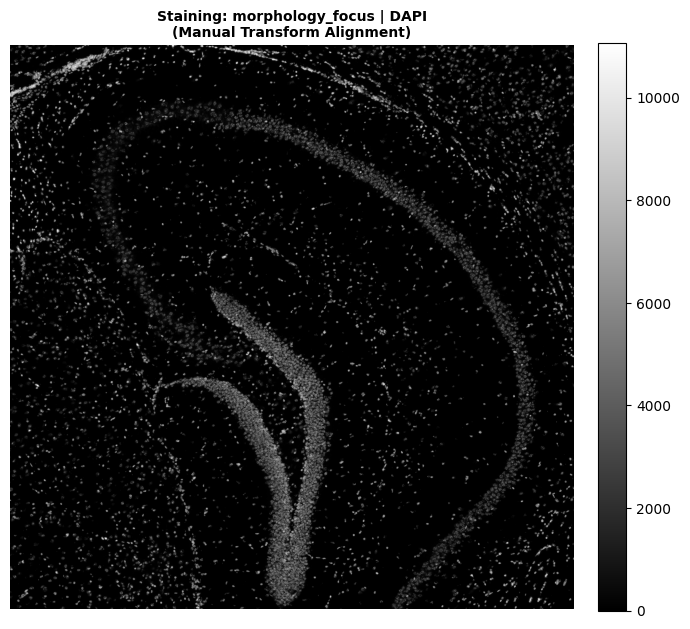

-> Successfully saved: staining_manual_transform_ATP1A1-CD45-E-Cadherin_roi_0_6000.pdf


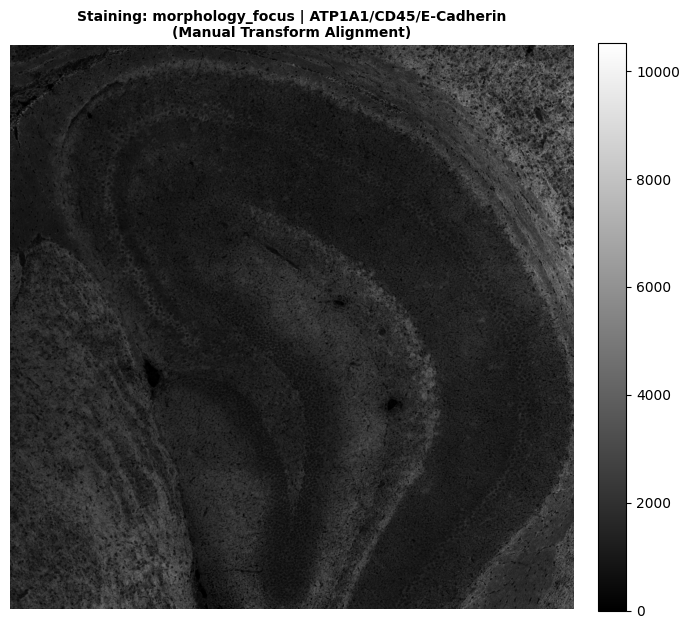

-> Successfully saved: staining_manual_transform_18S_roi_0_6000.pdf


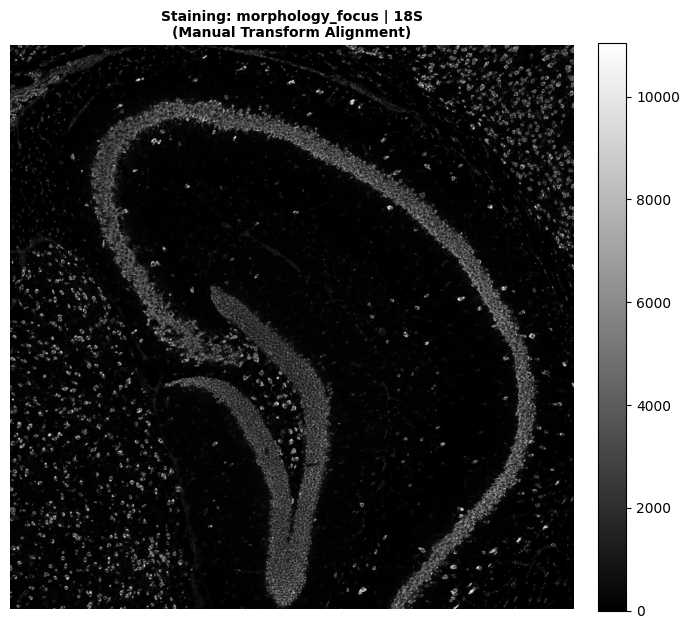

-> Successfully saved: staining_manual_transform_AlphaSMA-Vimentin_roi_0_6000.pdf


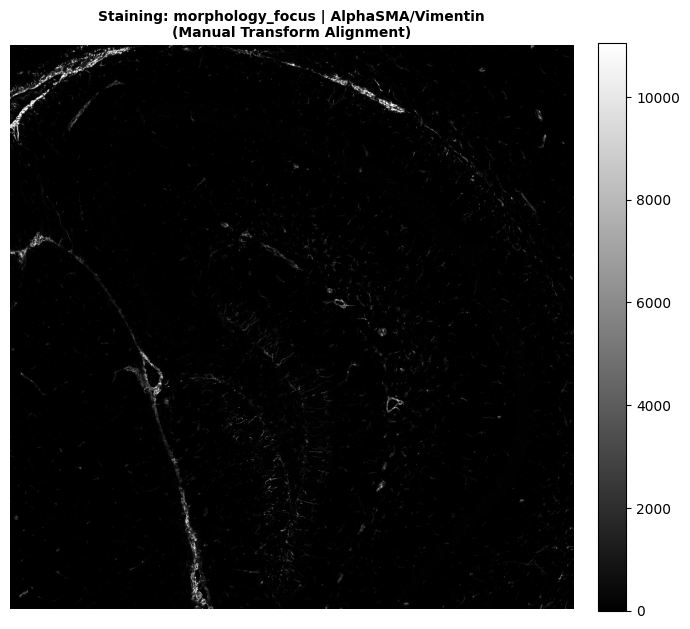

-> Successfully saved: staining_manual_transform_dummy_roi_0_6000.pdf


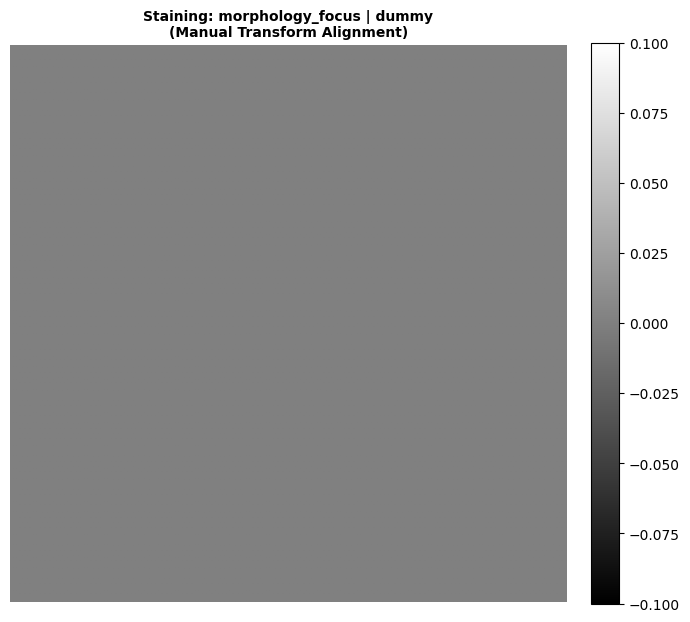

In [65]:
# Pull the base transcript array out of the Dask environment to acquire baseline ranges
transcripts_base_df = sdata["transcripts"].compute()
target_roi = (0, 6000, 0, 6000)

print("--- Initializing Manual Transformation Pipeline ---")
visualize_individual_stainings_manual(
    sdata=sdata,trans_df=transcripts_base_df,
    image_key="morphology_focus",scale_key="scale0",
    roi=target_roi,figsize=(7, 7),
    cmap="gray",saving_path=saving_path)

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def visualize_composite_staining_intensity_alpha(
    sdata,
    trans_df,  # Base transcripts dataframe for range calculation
    image_key: str = "morphology_focus",
    scale_key: str = "scale0",
    roi: tuple[float, float, float, float] | None = None,
    figsize: tuple[float, float] = (10, 10),
    include_channels: list[int] | None = None,  # NEW: Explicit list of channel indices to plot
    cmaps: list[str] | None = None,            # List of continuous colormaps matching selected channels
    title: str = "Composite Staining (Intensity-Based Alpha)",
    saving_path: Path | str | None = None,
    max_pct:float=98
):
    """
    Creates an aligned composite visualization of chosen staining channels.
    Pixels map their signal intensity directly to their transparency channel.
    Automatically excludes the final dummy channel.
    """
    print("\n=== [1/5] Transcript Global Ranges (Baseline calculation) ===")
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== [2/5] Raw Image Metadata (Scale0) ===")
    node = sdata.images[image_key][scale_key]
    img_dask_array = node.image.data if hasattr(node, "image") else node.data
    img_shape = img_dask_array.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== [3/5] Scaling Factor Derivation ===")
    scale_x, scale_y = img_w / t_dx, img_h / t_dy
    scale_factor = (scale_x + scale_y) / 2

    if roi is not None:
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = roi
        shifted_xmin, shifted_xmax = roi_xmin - t_xmin, roi_xmax - t_xmin
        shifted_ymin, shifted_ymax = roi_ymin - t_ymin, roi_ymax - t_ymin
        
        pixel_xmin = max(0, int(np.floor(shifted_xmin * scale_factor)))
        pixel_xmax = min(img_w, int(np.ceil(shifted_xmax * scale_factor)))
        pixel_ymin = max(0, int(np.floor(shifted_ymin * scale_factor)))
        pixel_ymax = min(img_h, int(np.ceil(shifted_ymax * scale_factor)))
        
        cropped_img_dask = img_dask_array[:, pixel_ymin:pixel_ymax, pixel_xmin:pixel_xmax]
    else:
        cropped_img_dask = img_dask_array
        roi_xmin, roi_xmax, roi_ymin, roi_ymax = t_xmin, t_xmax, t_ymin, t_ymax

    print("\n=== [4/5] Composite Processing (Filtering Selected Indices) ===")
    if "c" in node.coords:
        full_channel_names = [str(ch) for ch in node.coords["c"].values]
    else:
        full_channel_names = [f"Channel_{i}" for i in range(img_c)]
    
    # Baseline non-dummy channels list
    valid_channel_names = full_channel_names[:-1]
    
    # Compute the cropped pixel subset into RAM safely
    cropped_pixel_matrix = cropped_img_dask.compute()
    valid_pixel_data = cropped_pixel_matrix[:-1, :, :]
    
    # If no target subset is passed, default to all non-dummy indices
    if include_channels is None:
        include_channels = list(range(len(valid_channel_names)))
        
    final_channels_to_plot = []
    final_pixel_data_list = []
    
    for idx in include_channels:
        if idx >= len(valid_channel_names) or idx < 0:
            print(f"-> [WARNING] Requested index {idx} out of range or maps to dummy channel. Skipping.")
            continue
        final_channels_to_plot.append(valid_channel_names[idx])
        final_pixel_data_list.append(valid_pixel_data[idx, :, :])
        
    print(f"-> Actively plotting selected channels: {final_channels_to_plot} (Indices: {include_channels})")
    
    # Ensure fallback colormaps list aligns with the length of chosen channels
    if cmaps is None:
        standard_palette = ['Blues', 'Greens', 'Oranges', 'Reds', 'Purples', 'YlOrBr']
        cmaps = standard_palette[:len(final_channels_to_plot)]
        if len(cmaps) < len(final_channels_to_plot):
            cmaps += ['viridis'] * (len(final_channels_to_plot) - len(cmaps))

    if len(cmaps) < len(final_channels_to_plot):
        raise ValueError(f"Length of provided colormaps list ({len(cmaps)}) does not match selected channels ({len(final_channels_to_plot)})")

    # 5. Render and Export Figure using structural RGBA blending
    print("\n=== [5/5] Plotting Intensity-Alpha Blended Figure ===")
    fig, ax = plt.subplots(figsize=figsize)
    extent = [roi_xmin, roi_xmax, roi_ymin, roi_ymax]
    handles = [] 
    
    for idx, ch_name in enumerate(final_channels_to_plot):
        single_channel_data = final_pixel_data_list[idx]
        
        # Normalize intensities using robust percentiles to clean background noise
        v_min, v_max = np.percentile(single_channel_data, (1, max_pct))
        if v_max == v_min: v_max += 1e-5
        normalized_data = (single_channel_data - v_min) / (v_max - v_min)
        normalized_data = np.clip(normalized_data, 0, 1)
        
        # Convert the 2D intensity profile into a mapped 3D RGB grid based on colormap
        cmap_lookup = plt.get_cmap(cmaps[idx])
        rgba_image = cmap_lookup(normalized_data)  # (Y, X, 4)
        
        # Overwrite alpha layer directly with the normalized signal intensity
        rgba_image[..., 3] = normalized_data 
        
        # Render the pre-compiled RGBA layer
        ax.imshow(
            rgba_image, 
            origin="lower", 
            extent=extent
        )
        
        # Setup legend tags using the color high-point
        marker_color = cmap_lookup(0.8)
        handles.append(plt.Line2D([0], [0], color=marker_color, lw=4, label=ch_name))

    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.axis("off")
    ax.legend(handles=handles, title="Stainings", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    
    if saving_path is not None:
        save_dir = Path(saving_path)
        save_dir.mkdir(parents=True, exist_ok=True)
        roi_suffix = f"_roi_{int(roi_xmin)}_{int(roi_xmax)}" if roi is not None else ""
        ch_suffix = f"_channels_" + "_".join(map(str, include_channels))
        pdf_filename = f"staining_composite{ch_suffix}_intensity_alpha{roi_suffix}.pdf"
        
        fig.savefig(save_dir / pdf_filename, bbox_inches="tight", dpi=300)
        print(f"-> Intensity-alpha composite PDF saved: {pdf_filename}")
        
    plt.show()
    plt.close(fig)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_4300_4800.pdf


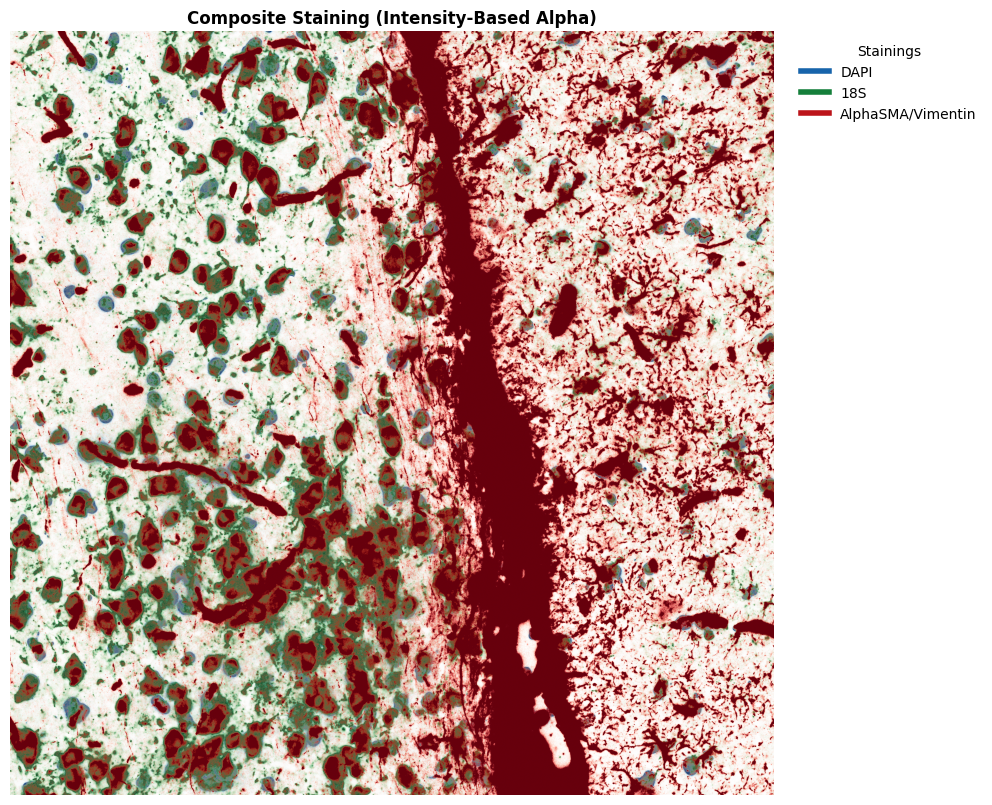

In [67]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4300, 4800, 1000, 1500),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=80.0
)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_intensity_alpha_roi_0_6000.pdf


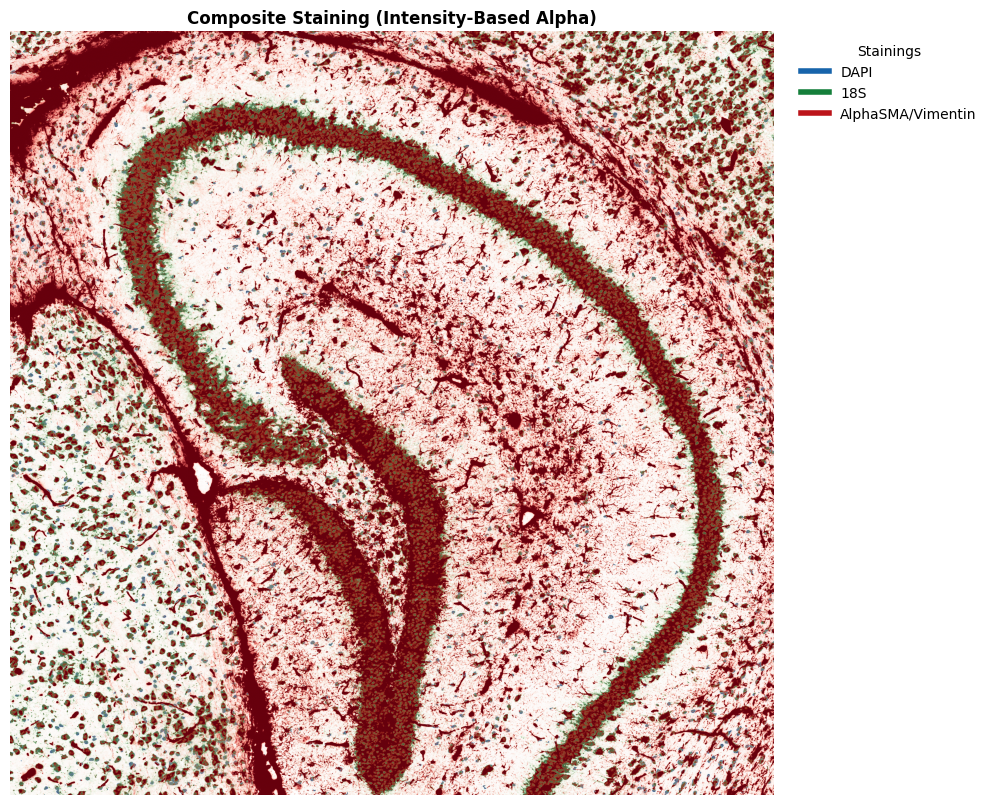

In [68]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(0, 6000, 0, 6000),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # 3 colormaps matching your 3 indices
    saving_path=saving_path,max_pct=80.0
)

# 1. Image structure quantification


=== STEP 1: Extracting XY Transcript Data ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Target ROI Transformation ===

=== STEP 5: Cumulative Autocorrelation Engine ===


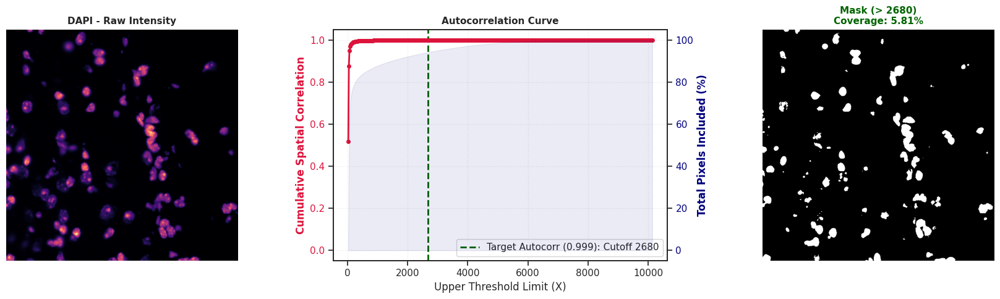

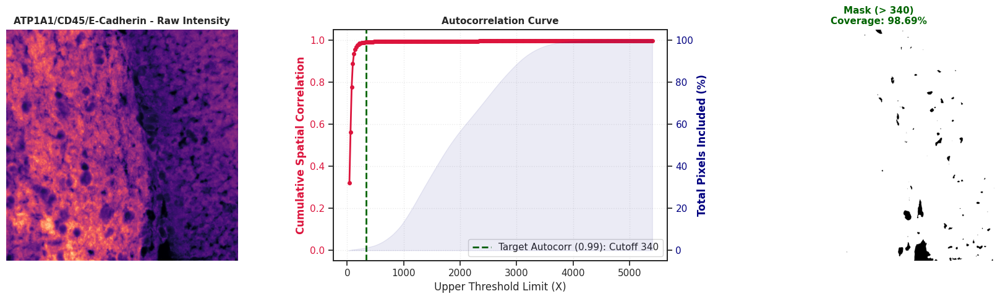

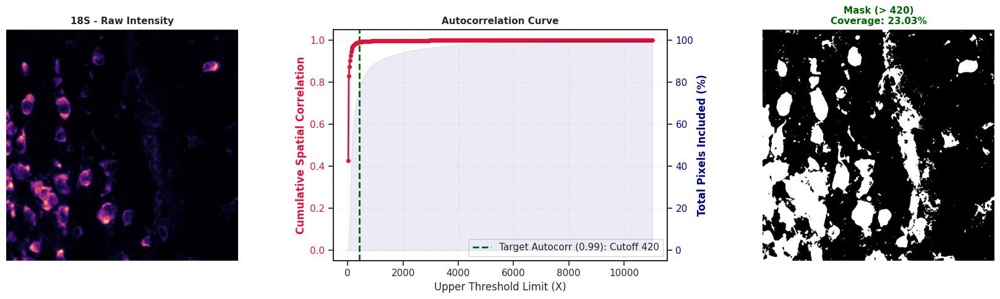

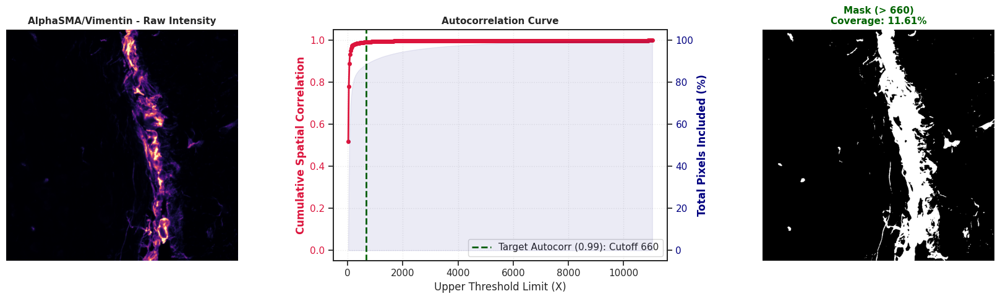

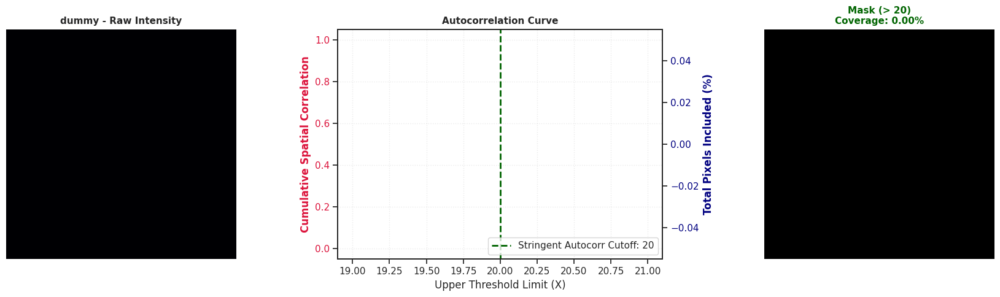

In [143]:
from pathlib import Path

# 1. Define where you want to save the diagnostic plots
# Change this path to wherever you want the output PNGs to land
# 2. Define your Region of Interest (ROI) using global transcript coordinates
# This 200x200 window is perfect for a fast, clear analysis
target_roi = (4500, 4700, 1100, 1300)

# 3. Call the cumulative function
df_summary=analyze_channels_and_get_thresholds(
    sdata=sdata,                         # Your main SpatialData object
    image_key="morphology_focus",        # The key to your morphology image
    scale_key="scale0",                  # 'scale0' for full resolution
    roi=target_roi,                      # Your spatial bounding window
    cmap="magma",                        # Perceptually uniform colormap
    saving_path=saving_path,             # Directory where plots will be saved
    step_size=20, mode="stringent",      # Calculates windows: 0->100, 0->200, 0->300, etc.
    threshold={'DAPI':0.999, 'ATP1A1/CD45/E-Cadherin':0.99, '18S':0.99, 'AlphaSMA/Vimentin':0.99, 'dummy':0.99}
    
)

#2. Staining intensity vs composition
The point of this plot is to illustrate some transcripts have a certain enrichment in positive areas of certain stainings (in uRNA space)

## Other plots and calculations here 

In [78]:
import pandas as pd
import numpy as np

def compute_urna_percentages(sdata, df_summary, extracellular_key='extracellular', extracellular_value=True):
    # 1. Extract and compute the transcripts DataFrame efficiently
    transcripts_df = sdata['transcripts'][[extracellular_key, 'gene']].compute()
    transcripts_df.index = transcripts_df.index.astype(str)
    
    # Filter for target transcripts (e.g., extracellular == True or overlaps_cell == False)
    # properly mapping strings/booleans dynamically
    is_extracellular = transcripts_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    filtered_transcripts = transcripts_df[is_extracellular]
    
    # Compute global total number of uRNA for each gene
    # This serves as our denominator for df_values
    df_total_urna = filtered_transcripts.groupby('gene').size().to_frame(name='total_uRNA')
    
    # 2. Extract the AnnData info
    intensity_adata = sdata['image_intensity_per_transcript']
    channels = intensity_adata.var_names.tolist()
    
    if hasattr(intensity_adata.X, "toarray"):
        intensities_matrix = intensity_adata.X.toarray()
    else:
        intensities_matrix = intensity_adata.X
        
    intensities_df = pd.DataFrame(
        intensities_matrix, 
        index=intensity_adata.obs_names.astype(str), 
        columns=channels
    )
    
    # 3. Join the datasets based on the transcript index
    # We join on filtered_transcripts so we only track the relevant subset moving forward
    merged_df = filtered_transcripts.join(intensities_df, how='inner')
    
    # 4. Prepare the reference dictionary for thresholds
    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    
    # Initialize dictionary to collect raw counts
    freqs_dict = {}  
    unique_genes = merged_df['gene'].unique()
    
    # 5. Calculate absolute uRNA counts per channel
    for channel in channels:
        if channel not in threshold_dict:
            continue
            
        threshold = threshold_dict[channel]
        
        # Filter for rows where intensity exceeds the channel threshold
        is_positive_area = merged_df[channel] > threshold
        pos_df = merged_df[is_positive_area]
        
        # Count occurrences per gene within the positive zone
        urna_in_pos = pos_df.groupby('gene').size()
        
        # Save absolute counts
        freqs_dict[channel] = urna_in_pos
        
    # 6. Format into final DataFrames
    df_freqs = pd.DataFrame(freqs_dict, index=unique_genes).fillna(0)
    
    # Clean up total uRNA dataframe index to match unique_genes
    df_total_urna = df_total_urna.reindex(unique_genes).fillna(0)
    
    # --- DF_VALUES EVALUATION ---
    # Divide the local counts per channel by the global uRNA total for each gene
    df_values = df_freqs.div(df_total_urna['total_uRNA'], axis=0) * 100
    df_values = df_values.fillna(0)  # Handle any division-by-zero safely
    
    # Clean up index names and data types
    df_freqs.index.name = 'gene'
    df_values.index.name = 'gene'
    df_total_urna.index.name = 'gene'
    df_total_urna = df_total_urna.astype(int)
    
    return df_freqs, df_values, df_total_urna

In [80]:
df_freqs, df_values, df_total_urna = compute_urna_percentages(sdata, df_summary)

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def filter_and_plot_urna(df_freqs, df_values, df_total_urna, n_counts=50, cmap='YlGnBu'):
    """
    Filters the precomputed uRNA dataframes based on a minimum global count threshold
    and generates a heatmap visualization.
    
    Parameters:
    - df_freqs: DataFrame of absolute uRNA counts per channel.
    - df_values: DataFrame of % of gene uRNA inside each channel.
    - df_total_urna: DataFrame of global total uRNA per gene.
    - n_counts: Minimum threshold of global uRNA counts required to keep a gene.
    - cmap: Colormap for the heatmap.
    
    Returns:
    - df_freqs_filtered, df_values_filtered, df_total_urna_filtered
    """
    # 1. Identify genes that meet the expression cutoff from the total counts
    passing_genes = df_total_urna[df_total_urna['total_uRNA'] >= n_counts].index
    
    # 2. Filter all 3 dataframes simultaneously using the passing genes
    df_freqs_filtered = df_freqs.loc[df_freqs.index.isin(passing_genes)]
    df_values_filtered = df_values.loc[df_values.index.isin(passing_genes)]
    df_total_urna_filtered = df_total_urna.loc[df_total_urna.index.isin(passing_genes)]
    
    print(f"--- Filtering Summary (Threshold: >= {n_counts} global counts) ---")
    print(f"Original unique genes: {len(df_total_urna)}")
    print(f"Genes matching criteria: {len(passing_genes)}")
    print(f"Filtered out: {len(df_total_urna) - len(passing_genes)} genes\n")
    
    if df_values_filtered.empty:
        print("Warning: The filtered DataFrame is empty. Try lowering n_counts.")
        return df_freqs_filtered, df_values_filtered, df_total_urna_filtered

    
    return df_freqs_filtered, df_values_filtered, df_total_urna_filtered


In [82]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.affinity import affine_transform

def compute_spatial_pixel_sharing(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries"
):
    """
    Calculates the percentage of positive pixels inside vs outside cells 
    for each channel using a manual isotropic scaling transformation.
    """
    print("=== STEP 1: Transcript Global Ranges ===")
    trans_df = sdata['transcripts'][['x', 'y']].compute()
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    
    t_dx = t_xmax - t_xmin
    t_dy = t_ymax - t_ymin
    print(f"Global Transcripts Bounds -> X: [{t_xmin:.2f} to {t_xmax:.2f}] (Delta: {t_dx:.2f})")
    print(f"Global Transcripts Bounds -> Y: [{t_ymin:.2f} to {t_ymax:.2f}] (Delta: {t_dy:.2f})")

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # Expecting (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]
    print(f"Raw Image Shape (c, y, x): {img_shape}")

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    # Calculate scale factor between the spatial bounding span vs the pixel canvas dimensions
    scale_x = img_w / t_dx
    scale_y = img_h / t_dy
    # Averaging to match identical proportional isotropic scaling
    scale_factor = (scale_x + scale_y) / 2
    print(f"Calculated Scale Factor (Pixels per Spatial Unit): {scale_factor:.5f}")

    print("\n=== STEP 4: Manual Geometry Transformation ===")
    # Load cell boundaries directly into a GeoDataFrame
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")

    # Mirror your manual transform matrix: Shift to 0,0 baseline and scale up to pixel grid
    # x_pixel = (x - t_xmin) * scale_factor
    # y_pixel = (y - t_ymin) * scale_factor
    # Affine matrix format: [a, b, d, e, xoff, yoff]
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    print("\n=== STEP 5: Generating Binary Cell Mask ===")
    # Use OpenCV to rasterize the transformed polygons directly into a pixel grid
    import cv2
    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: 
            continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    # Total area metrics
    total_pixels_inside = np.sum(cell_mask == 1)
    total_pixels_outside = np.sum(cell_mask == 0)
    print(f"Cell Mask Generated -> Pixels Inside: {total_pixels_inside} | Pixels Outside: {total_pixels_outside}")

    # Extract existing channel coordinate markers
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 6: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        
        # Pull single channel slice into memory safely
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        # Calculate boolean mask of pixels strictly exceeding threshold
        pos_mask = img_np > threshold
        
        # Intersect threshold mask with cellular compartments
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_outside = np.sum((pos_mask == True) & (cell_mask == 0))
        
        # Calculate final percentages based on total available pixels in that compartment
        pct_inside = (pos_inside / total_pixels_inside) * 100 if total_pixels_inside > 0 else 0
        pct_outside = (pos_outside / total_pixels_outside) * 100 if total_pixels_outside > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Outside Cells / Extracellular)": pct_outside
        })
        print(f"-> {ch_name}: Inside={pct_inside:.2f}%, Outside (Extracellular)={pct_outside:.2f}%")
        
    df_spatial_summary = pd.DataFrame(spatial_results)
    print("\n✓ Spatial threshold breakdown completed successfully.")
    return df_spatial_summary

In [83]:
# Step 1: Run the new spatial compartment mask calculator
# This replaces your old df_summary with a version calculated only on extracellular space
df_spatial_summary = compute_spatial_pixel_sharing(
    sdata=sdata, 
    df_summary=df_summary,
    image_key="morphology_focus",  # Change if your image key is named differently
    scale_key="scale0",
    shapes_key="cell_boundaries"
)


=== STEP 1: Transcript Global Ranges ===
Global Transcripts Bounds -> X: [4069.39 to 5779.78] (Delta: 1710.39)
Global Transcripts Bounds -> Y: [977.52 to 2953.72] (Delta: 1976.20)

=== STEP 2: Raw Image Matrix Dimensions ===
Raw Image Shape (c, y, x): (5, 9300, 8049)

=== STEP 3: Scaling Factor Derivation ===
Calculated Scale Factor (Pixels per Spatial Unit): 4.70597

=== STEP 4: Manual Geometry Transformation ===

=== STEP 5: Generating Binary Cell Mask ===
Cell Mask Generated -> Pixels Inside: 16994595 | Pixels Outside: 57861105

=== STEP 6: Processing Channels and Computing Compartment Positivity ===
-> DAPI: Inside=90.18%, Outside (Extracellular)=4.25%
-> ATP1A1/CD45/E-Cadherin: Inside=99.65%, Outside (Extracellular)=99.42%
-> 18S: Inside=83.78%, Outside (Extracellular)=8.42%
-> AlphaSMA/Vimentin: Inside=9.17%, Outside (Extracellular)=1.80%
-> dummy: Inside=0.00%, Outside (Extracellular)=0.00%

✓ Spatial threshold breakdown completed successfully.


In [84]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from shapely.affinity import affine_transform
import cv2

def compute_spatial_pixel_sharing_with_cell_like(
    sdata, 
    df_summary, 
    image_key: str = "morphology_focus", 
    scale_key: str = "scale0", 
    shapes_key: str = "cell_boundaries",
    extracellular_key: str = "extracellular",
    extracellular_value: bool = False,
    overlaps_cell_key: str = "overlaps_cell",
    overlaps_cell_value: bool = False,
    cell_like_dilation_radius: int = 15,
    show_viz: bool = True
):
    """
    Calculates the percentage of positive pixels across 3 compartments:
    Inside Cells, Cell-Like Regions (Unsegmented), and True Extracellular space.
    Includes a diagnostic visualization of the generated masks.
    """
    print("=== STEP 1: Transcript Global Ranges & Filtering ===")
    trans_df = sdata['transcripts'][['x', 'y', extracellular_key, overlaps_cell_key]].compute()
    trans_df.index = trans_df.index.astype(str)
    
    t_xmin, t_xmax = trans_df['x'].min(), trans_df['x'].max()
    t_ymin, t_ymax = trans_df['y'].min(), trans_df['y'].max()
    t_dx, t_dy = t_xmax - t_xmin, t_ymax - t_ymin

    print("\n=== STEP 2: Raw Image Matrix Dimensions ===")
    node = sdata.images[image_key][scale_key]
    img_data = node.image if hasattr(node, "image") else node
    img_shape = img_data.shape  # (c, y, x)
    img_c, img_h, img_w = img_shape[0], img_shape[1], img_shape[2]

    print("\n=== STEP 3: Scaling Factor Derivation ===")
    scale_factor = ((img_w / t_dx) + (img_h / t_dy)) / 2

    print("\n=== STEP 4: Creating Mask 1 - Inside Cells ===")
    cb = sdata[shapes_key]
    gdf = gpd.GeoDataFrame(cb.copy(), geometry="geometry")
    pixel_matrix = [scale_factor, 0, 0, scale_factor, -t_xmin * scale_factor, -t_ymin * scale_factor]
    gdf['pixel_geometry'] = gdf['geometry'].apply(lambda g: affine_transform(g, pixel_matrix))

    cell_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for geom in gdf['pixel_geometry']:
        if geom.is_empty: continue
        if geom.geom_type == 'Polygon':
            ext_coords = np.array(geom.exterior.coords, dtype=np.int32)
            cv2.fillPoly(cell_mask, [ext_coords], 1)
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                ext_coords = np.array(poly.exterior.coords, dtype=np.int32)
                cv2.fillPoly(cell_mask, [ext_coords], 1)

    print("\n=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===")
    # Filter using string-safe matching for whatever values you pass down
    is_extra_match = trans_df[extracellular_key].astype(str).str.lower() == str(extracellular_value).lower()
    is_cell_match = trans_df[overlaps_cell_key].astype(str).str.lower() == str(overlaps_cell_value).lower()
    
    cell_like_transcripts = trans_df[is_extra_match & is_cell_match]
    print(f"Found {len(cell_like_transcripts)} cell-like transcripts matching target criteria.")
    
    # Map points to pixel grid space
    cl_x_pixel = np.clip(((cell_like_transcripts['x'] - t_xmin) * scale_factor).astype(int), 0, img_w - 1)
    cl_y_pixel = np.clip(((cell_like_transcripts['y'] - t_ymin) * scale_factor).astype(int), 0, img_h - 1)
    
    # Rasterize points and dilate to form regional structural masks
    cell_like_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    cell_like_mask[cl_y_pixel, cl_x_pixel] = 1
    
    if cell_like_dilation_radius > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (cell_like_dilation_radius, cell_like_dilation_radius))
        cell_like_mask = cv2.dilate(cell_like_mask, kernel)
    
    # Enforce priority rules (Segmented cell boundaries override cell-like transcripts)
    cell_like_mask[cell_mask == 1] = 0

    print("\n=== STEP 6: Creating Mask 3 - True Extracellular Space ===")
    true_extracellular_mask = np.where((cell_mask == 0) & (cell_like_mask == 0), 1, 0).astype(np.uint8)

    # Compute total area metrics per compartment
    total_inside = np.sum(cell_mask == 1)
    total_cell_like = np.sum(cell_like_mask == 1)
    total_true_extra = np.sum(true_extracellular_mask == 1)
    
    print(f"-> Compartment Areas (Pixels) | Inside Cells: {total_inside} | Cell-Like: {total_cell_like} | True Extracellular: {total_true_extra}")

    # --- Diagnostic Visualization ---
    if show_viz:
        print("\n=== Rendering Spatial Compartment Visualization ===")
        viz_map = np.zeros((img_h, img_w), dtype=np.uint8)
        viz_map[true_extracellular_mask == 1] = 0
        viz_map[cell_like_mask == 1] = 1
        viz_map[cell_mask == 1] = 2
        
        fig, ax = plt.subplots(figsize=(6, 6))
        cmap_custom = ListedColormap(['#ECEFF1', '#FFCC80', '#90CAF9'])  # Gray=Extra, Orange=Cell-Like, Blue=Inside Cell
        
        im = ax.imshow(viz_map, cmap=cmap_custom, origin='lower')
        ax.set_title("Generated Spatial Compartment Masks", fontweight='bold')
        ax.axis('off')
        
        cbar = plt.colorbar(im, ax=ax, ticks=[0.33, 1.0, 1.66], fraction=0.046, pad=0.04)
        cbar.ax.set_yticklabels(['True Extracellular', 'Cell-Like Region', 'Inside Cell'])
        plt.show()

    # --- Step 7: Signal Intensity Analysis ---
    if "c" in img_data.coords:
        channel_names = [str(ch) for ch in img_data.coords["c"].values]
    else:
        channel_names = [f"Channel_{i}" for i in range(img_c)]

    threshold_dict = dict(zip(df_summary['Channel Name'], df_summary['Intensity Threshold']))
    spatial_results = []

    print("\n=== STEP 7: Processing Channels and Computing Compartment Positivity ===")
    for idx, ch_name in enumerate(channel_names):
        if ch_name not in threshold_dict:
            continue
            
        threshold = threshold_dict[ch_name]
        channel_slice = img_data[idx, :, :].compute() if hasattr(img_data, "compute") else img_data[idx, :, :]
        img_np = np.asarray(channel_slice)
        
        pos_mask = img_np > threshold
        
        pos_inside = np.sum((pos_mask == True) & (cell_mask == 1))
        pos_cell_like = np.sum((pos_mask == True) & (cell_like_mask == 1))
        pos_true_extra = np.sum((pos_mask == True) & (true_extracellular_mask == 1))
        
        pct_inside = (pos_inside / total_inside) * 100 if total_inside > 0 else 0
        pct_cell_like = (pos_cell_like / total_cell_like) * 100 if total_cell_like > 0 else 0
        pct_true_extra = (pos_true_extra / total_true_extra) * 100 if total_true_extra > 0 else 0
        
        spatial_results.append({
            "Channel Name": ch_name,
            "Intensity Threshold": threshold,
            "% Positive Pixels (Inside Cells)": pct_inside,
            "% Positive Pixels (Cell-Like Regions)": pct_cell_like,
            "% Positive Pixels (True Extracellular)": pct_true_extra
        })
        print(f"-> {ch_name}: Inside={pct_inside:.1f}% | Cell-Like={pct_cell_like:.1f}% | True Extra={pct_true_extra:.1f}%")
        
    return pd.DataFrame(spatial_results)

=== STEP 1: Transcript Global Ranges & Filtering ===

=== STEP 2: Raw Image Matrix Dimensions ===

=== STEP 3: Scaling Factor Derivation ===

=== STEP 4: Creating Mask 1 - Inside Cells ===

=== STEP 5: Creating Mask 2 - Cell-Like Regions (From Transcripts) ===
Found 2597144 cell-like transcripts matching target criteria.

=== STEP 6: Creating Mask 3 - True Extracellular Space ===
-> Compartment Areas (Pixels) | Inside Cells: 16994595 | Cell-Like: 1968849 | True Extracellular: 55892256

=== Rendering Spatial Compartment Visualization ===


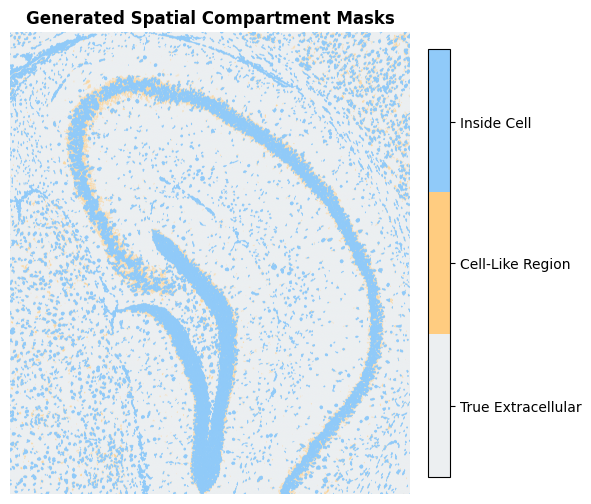


=== STEP 7: Processing Channels and Computing Compartment Positivity ===
-> DAPI: Inside=90.2% | Cell-Like=23.8% | True Extra=3.6%
-> ATP1A1/CD45/E-Cadherin: Inside=99.6% | Cell-Like=99.9% | True Extra=99.4%
-> 18S: Inside=83.8% | Cell-Like=74.7% | True Extra=6.1%
-> AlphaSMA/Vimentin: Inside=9.2% | Cell-Like=3.4% | True Extra=1.7%
-> dummy: Inside=0.0% | Cell-Like=0.0% | True Extra=0.0%


In [85]:
df_spatial_summary = compute_spatial_pixel_sharing_with_cell_like(
    sdata=sdata,
    df_summary=df_summary,
    image_key="morphology_focus",
    shapes_key="cell_boundaries",
    extracellular_key="extracellular",
    extracellular_value=False,
    overlaps_cell_key="overlaps_cell",
    overlaps_cell_value=False,
    cell_like_dilation_radius=0,  # Radius in pixels to grow around unsegmented transcripts
    show_viz=True
)

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_spatial_compartment_summary(df_spatial_summary: pd.DataFrame, title: str = "Signal Positivity Across Spatial Compartments"):
    """
    Creates a grouped bar chart visualizing the percentage of positive pixels 
    across Inside Cells, Cell-Like Regions, and True Extracellular space.
    """
    # 1. Melt the DataFrame from wide to long format for Seaborn compatibility
    melt_cols = [
        "% Positive Pixels (Inside Cells)", 
        "% Positive Pixels (Cell-Like Regions)", 
        "% Positive Pixels (True Extracellular)"
    ]
    
    # Ensure columns exist before melting
    available_cols = [col for col in melt_cols if col in df_spatial_summary.columns]
    
    df_long = df_spatial_summary.melt(
        id_vars=["Channel Name"], 
        value_vars=available_cols,
        var_name="Compartment", 
        value_name="Percent Positive Pixels"
    )
    
    # 2. Clean up the legend labels for display readability
    df_long["Compartment"] = df_long["Compartment"].str.extract(r"\((.*?)\)")

    # 3. Initialize the plot
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Use an elegant color scheme matching the spatial mask visualization palette
    palette_dict = {
        "Inside Cells": "#90CAF9",          # Blue
        "Cell-Like Regions": "#FFCC80",     # Orange
        "True Extracellular": "#90A4AE"     # Muted Gray-Blue
    }
    
    sns.barplot(
        data=df_long, 
        x="Channel Name", 
        y="Percent Positive Pixels", 
        hue="Compartment", 
        palette=palette_dict,
        edgecolor="black",
        linewidth=0.7,
        ax=ax
    )
    
    # 4. Refine structural aesthetics
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
    
    # Titles and Label refinement
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Imaging Channels", fontsize=12, labelpad=10)
    ax.set_ylabel("% Area Exceeding Threshold", fontsize=12, labelpad=10)
    
    # Keep the bounds locked inside normal percentages
    ax.set_ylim(0, max(df_long["Percent Positive Pixels"].max() * 1.15, 10))
    
    # Finalize Layout layout
    plt.legend(frameon=False, loc="upper right", title="Compartment")
    plt.tight_layout()
    plt.show()

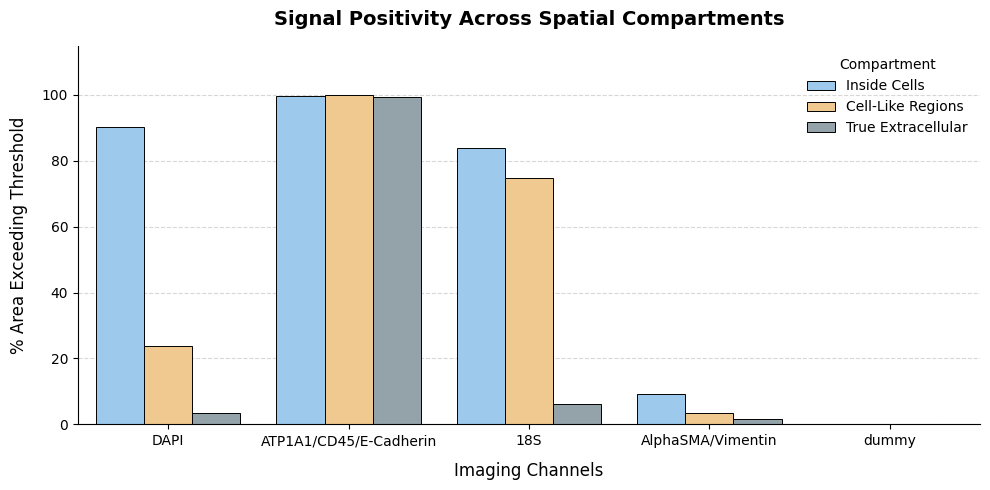

In [87]:
plot_spatial_compartment_summary(df_spatial_summary)

In [88]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

def metric_scatter_extracellular(
    df_values: pd.DataFrame,
    df_spatial_summary: pd.DataFrame,
    x: str,
    y: str,
    baselines_mode: str = "background",  # Options: "background", "cell_like", "all"
    x_baselines: list[str] | None = None,
    y_baselines: list[str] | None = None,
    size: int = 15,
    label_top_n_x: int = 0,
    label_top_n_y: int = 0,
    label_bottom_n_x: int = 0,
    label_bottom_n_y: int = 0,
    title: str | None = None,
    linewidth: float = 0.5,
    figures_path: str = "",
    save: bool = False,
    custom_plot_filename: str = None,
    dot_color: str = "#1E90FF",
    gene_label: str = "Gene probes",
) -> None:
    """
    Creates a scatter plot comparing uRNA percentages of two specified channels (x and y).
    Draws custom horizontal and vertical lines indicating expected random positivity thresholds.
    
    Parameters:
    -----------
    baselines_mode : str
        Determines which baseline thresholds to draw.
        - "background": Only True Extracellular
        - "cell_like": True Extracellular AND Cell-Like Regions
        - "all": All three thresholds (True Extracellular, Cell-Like, and Inside Cells)
    """
    # --- Illustrator Editability Settings ---
    mpl.rcParams['pdf.fonttype'] = 42  
    mpl.rcParams['ps.fonttype'] = 42   

    # 1. Clean and isolate data from the metrics matrix (df_values)
    if x not in df_values.columns or y not in df_values.columns:
        raise ValueError(f"Ensure both axis channels '{x}' and '{y}' exist as columns in df_values.")
        
    plot_df = df_values[[x, y]].copy()
    plot_df.dropna(subset=[x, y], inplace=True)

    # 2. Map the baseline selection mode
    baseline_mapping = {
        "background": [
            "% Positive Pixels (True Extracellular)"
        ],
        "cell_like": [
            "% Positive Pixels (True Extracellular)", 
            "% Positive Pixels (Cell-Like Regions)"
        ],
        "all": [
            "% Positive Pixels (True Extracellular)", 
            "% Positive Pixels (Cell-Like Regions)", 
            "% Positive Pixels (Inside Cells)"
        ]
    }

    if baselines_mode not in baseline_mapping:
        raise ValueError("baselines_mode must be one of: 'background', 'cell_like', or 'all'")

    # Use explicit manual baselines if provided, otherwise default to the mapped mode
    actual_x_baselines = x_baselines if x_baselines is not None else baseline_mapping[baselines_mode]
    actual_y_baselines = y_baselines if y_baselines is not None else baseline_mapping[baselines_mode]

    # 3. Build the plot setup
    fig, ax = plt.subplots(figsize=(6, 6))
    
    ax.scatter(
        plot_df[x], plot_df[y], 
        color=dot_color, 
        edgecolor="black", 
        s=size, 
        linewidth=linewidth, 
        alpha=0.9,
        zorder=5  # Keep dots on top of all lines
    )

    # Clean up spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Filter spatial summary for the target channels
    x_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == x]
    y_summary = df_spatial_summary[df_spatial_summary['Channel Name'] == y]

    # Assign distinct colors and styles if plotting multiple distinct compartment lines
    style_palette = {
        "% Positive Pixels (True Extracellular)": {"color": "#DC143C", "ls": "--", "label": "True Extra"},
        "% Positive Pixels (Cell-Like Regions)": {"color": "#FF8C00", "ls": "-.", "label": "Cell-Like"},
        "% Positive Pixels (Inside Cells)": {"color": "#4169E1", "ls": ":", "label": "Inside Cell"}
    }
    
    # Track values to safely expand the plot limits later
    all_baseline_x_vals = []
    all_baseline_y_vals = []
    used_labels = set()

    # 4. Draw requested vertical lines (X-axis channels)
    if not x_summary.empty:
        for col in actual_x_baselines:
            if col in x_summary.columns:
                val = x_summary[col].values[0]
                all_baseline_x_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axvline(x=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 5. Draw requested horizontal lines (Y-axis channels)
    if not y_summary.empty:
        for col in actual_y_baselines:
            if col in y_summary.columns:
                val = y_summary[col].values[0]
                all_baseline_y_vals.append(val)
                style = style_palette.get(col, {"color": "#7F8C8D", "ls": "--", "label": col})
                ax.axhline(y=val, color=style["color"], linestyle=style["ls"], linewidth=1.2, zorder=2)
                used_labels.add((style["color"], style["ls"], f"{style['label']} Baseline"))

    # 6. Label Handling
    label_genes = set()
    if label_top_n_x > 0:
        label_genes.update(plot_df.nlargest(label_top_n_x, x).index)
    if label_top_n_y > 0:
        label_genes.update(plot_df.nlargest(label_top_n_y, y).index)
    if label_bottom_n_x > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_x, x).index)
    if label_bottom_n_y > 0:
        label_genes.update(plot_df.nsmallest(label_bottom_n_y, y).index)

    texts = []
    for gene in label_genes:
        texts.append(
            ax.text(plot_df.loc[gene, x], plot_df.loc[gene, y], gene, fontsize=11, ha="right")
        )

    # 7. Graph limit bounding with dynamic baseline safe-padding
    x_min, x_max = plot_df[x].min(), plot_df[x].max()
    y_min, y_max = plot_df[y].min(), plot_df[y].max()
    
    if all_baseline_x_vals:
        x_min = min(x_min, min(all_baseline_x_vals))
        x_max = max(x_max, max(all_baseline_x_vals))
    if all_baseline_y_vals:
        y_min = min(y_min, min(all_baseline_y_vals))
        y_max = max(y_max, max(all_baseline_y_vals))

    x_padding = max((x_max - x_min) * 0.1, 5)
    y_padding = max((y_max - y_min) * 0.1, 5)

    ax.set_xlim(max(0, x_min - x_padding), min(105, x_max + x_padding))
    ax.set_ylim(max(0, y_min - y_padding), min(105, y_max + y_padding))

    if texts:
        adjust_text(texts, arrowprops={"arrowstyle": "-", "color": "black", "lw": 1})

    # 8. Label assignments
    ax.set_xlabel(f"{x.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)
    ax.set_ylabel(f"{y.replace('_', ' ').title()} (% uRNA Positivity)", fontsize=12)

    if title:
        ax.set_title(title, fontsize=14, fontweight="bold")

    # 9. Dynamic Legend Generation
    # 9. Dynamic Legend Generation
    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label=gene_label, markerfacecolor=dot_color, markeredgecolor="black", markersize=8)
    ]
    for color, ls, lbl in sorted(used_labels, key=lambda item: item[2]):
        legend_elements.append(Line2D([0], [0], color=color, linestyle=ls, linewidth=1.2, label=lbl))
        
    ax.legend(handles=legend_elements, loc="best", frameon=False)
    ax.tick_params(labelsize=10)

    if save:
        fig_dir = Path(figures_path)
        fig_dir.mkdir(parents=True, exist_ok=True)
        
        # --- NEW: File-system safe string cleaning for slashes ---
        safe_x = x.replace("/", "_")
        safe_y = y.replace("/", "_")
        
        plot_filename = custom_plot_filename or f"{safe_x}_vs_{safe_y}_compartments_scatter.pdf"
        plt.savefig(fig_dir / plot_filename, bbox_inches="tight")

    plt.show()

In [89]:
selgenes=sdata['xrna_metadata'].var[sdata['xrna_metadata'].var['logfoldchange_over_noise']>4].index
df_v=df_values[df_values.index.isin(selgenes)]
print(df_v.shape)

(2483, 5)


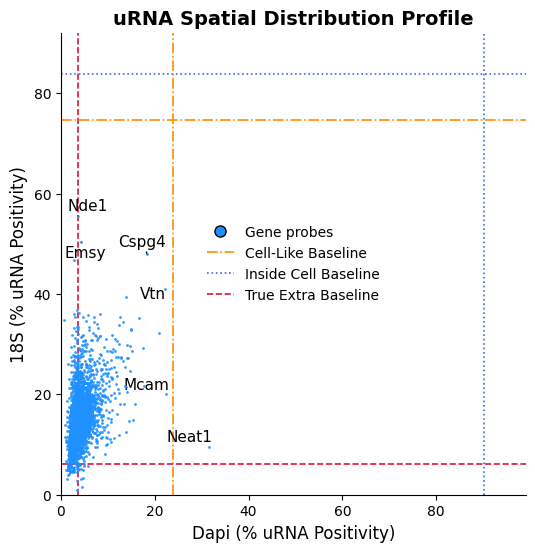

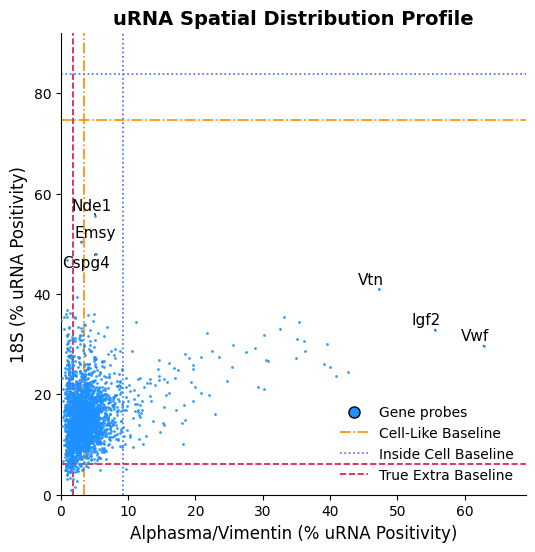

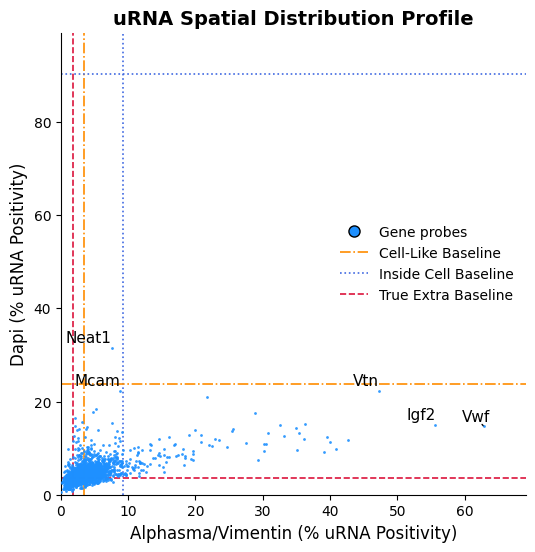

In [90]:
metric_scatter_extracellular( df_values=df_v,
    df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],save=True,figures_path=saving_path,
    x='DAPI', y='18S', label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=0,label_bottom_n_y=0,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,
    x='AlphaSMA/Vimentin', y='18S',x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],save=True,figures_path=saving_path,
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=0,label_bottom_n_y=0,
    title="uRNA Spatial Distribution Profile")

metric_scatter_extracellular(
    df_values=df_v,df_spatial_summary=df_spatial_summary,x_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],y_baselines= [ '% Positive Pixels (Inside Cells)',
       '% Positive Pixels (Cell-Like Regions)',
       '% Positive Pixels (True Extracellular)'],save=True,
    x='AlphaSMA/Vimentin', y='DAPI',figures_path=saving_path,
    label_top_n_x=3,linewidth=0.0, label_top_n_y=3,size=4,label_bottom_n_x=0,label_bottom_n_y=0,
    title="uRNA Spatial Distribution Profile")

# 2. Gene-category positive-pixel enrichment (permutation test)

Every transcript is assigned to exactly one spatial category:
- `intracellular`: `overlaps_cell == True`
- `cell_like`: `overlaps_cell == False` and `extracellular == False`
- `high_density`: `overlaps_cell == False`, `extracellular == True` and `enrichment_class == 'High Density'`
- `other`: everything else

For each channel we already binarized pixels into positive/negative using the cumulative-autocorrelation
thresholds in `df_summary` (Step 5 above). For every gene within every category we compute the observed
% of its transcripts landing on positive pixels of each channel, and build a null distribution by
permuting the positive/negative pixel labels among the transcripts of that category (this keeps each
category's overall positive-pixel rate fixed, and only randomizes which individual transcripts carry the
positive label, i.e. which gene happens to "get" them).

In [144]:
trans_positivity, channel_names_for_enrichment = compute_transcript_pixel_positivity(sdata, df_summary)
trans_positivity = assign_transcript_categories(trans_positivity)
trans_positivity["transcript_category"].value_counts()


=== Flagging per-transcript pixel positivity per channel ===
-> DAPI: 21.26% of transcripts on positive pixels
-> ATP1A1/CD45/E-Cadherin: 99.78% of transcripts on positive pixels
-> 18S: 73.12% of transcripts on positive pixels
-> AlphaSMA/Vimentin: 6.42% of transcripts on positive pixels
-> dummy: 0.00% of transcripts on positive pixels


transcript_category
intracellular    15440195
other             4544998
cell_like         2597144
high_density      1208419
Name: count, dtype: int64

In [145]:
df_gene_category_enrichment = compute_gene_category_pixel_enrichment(
    trans_positivity,
    channel_names=channel_names_for_enrichment,
    n_perm=200,
    min_transcripts=100,
    seed=0,
)
df_gene_category_enrichment.sort_values("pvalue_adj").head(20)


=== Category 'intracellular' (15427010 transcripts, 3947 genes passing min_transcripts) ===


100%|██████████| 5/5 [12:50<00:00, 154.04s/it]


=== Category 'cell_like' (2596117 transcripts, 2642 genes passing min_transcripts) ===


100%|██████████| 5/5 [01:29<00:00, 17.89s/it]


=== Category 'high_density' (1208266 transcripts, 2170 genes passing min_transcripts) ===


100%|██████████| 5/5 [00:40<00:00,  8.06s/it]


=== Category 'other' (4544672 transcripts, 3031 genes passing min_transcripts) ===


100%|██████████| 5/5 [02:38<00:00, 31.76s/it]


,gene,category,channel,n_transcripts,pct_positive_observed,pct_positive_expected_random,pct_positive_expected_std,enrichment_ratio,pvalue,pvalue_adj
184,Psen2,intracellular,DAPI,966,38.612836,32.818323,1.553086,1.176563,0.004975,0.009519
90,Snx5,intracellular,DAPI,5072,37.854890,32.669854,0.681597,1.158710,0.004975,0.009519
160,Slk,intracellular,DAPI,7154,41.235672,32.772715,0.580842,1.258232,0.004975,0.009519
168,Prr5,intracellular,DAPI,1010,44.059406,32.747030,1.416568,1.345447,0.004975,0.009519
169,Ryr2,intracellular,DAPI,11551,45.554497,32.741191,0.419898,1.391351,0.004975,0.009519
172,Cdh20,intracellular,DAPI,1630,44.355828,32.830368,1.152569,1.351061,0.004975,0.009519
175,Psat1,intracellular,DAPI,3387,39.533510,32.699882,0.790383,1.208980,0.004975,0.009519
60,Csnk1d,intracellular,DAPI,7357,35.462825,32.674188,0.552657,1.085347,0.004975,0.009519
156,Prpf3,intracellular,DAPI,777,38.223938,32.847490,1.593671,1.163679,0.004975,0.009519
157,Prpf31,intracellular,DAPI,1453,35.856848,32.644873,1.133559,1.098391,0.004975,0.009519


In [146]:
df_gene_category_enrichment.to_csv(os.path.join(saving_path,'gene_enrichment_vs_categories.csv'))

In [150]:
df_summary.to_csv(os.path.join(saving_path,'df_summary.csv'))

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_significant_gene_counts(
    df_gene_category_enrichment: pd.DataFrame,
    alpha: float = 0.05,
    title: str = "Genes enriched in positive pixels per channel",
    logfc_threshold:float=0.25
):
    """
    Stacked bar plot of FDR-significant enriched genes segmented by positive logFC tiers
    per channel and category.
    """
    df = df_gene_category_enrichment.copy()
    
    # 1. Compute logFC (Log2 of enrichment ratio)
    df["logFC"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    
    # 2. Filter for significant AND positive logFC >= 0.25
    sig = df[(df["pvalue_adj"] < alpha) & (df["logFC"] >= logfc_threshold)].copy()
    
    if sig.empty:
        print("No significant genes met the criteria (FDR < alpha and logFC >= 0.25).")
        return

    # 3. Bin logFC values into your exact specified intervals
    bins = [0.25, 0.5, 1.0, 2.0, 4.0, np.inf]
    labels = ["0.25-0.5", "0.5-1", "1-2", "2-4", "+4"]
    sig["logFC_tier"] = pd.cut(sig["logFC"], bins=bins, labels=labels, include_lowest=True)
    
    # 4. Count genes per condition and tier
    counts = sig.groupby(["channel", "category", "logFC_tier"], observed=False).size().reset_index(name="n_genes")
    
    # 5. Pivot data for stacked plotting (Rows = X-axis groups, Columns = Stack layers)
    pivot_df = counts.pivot(
        index=["channel", "category"], 
        columns="logFC_tier", 
        values="n_genes"
    ).fillna(0)
    
    # Ensure correct column order for stacking
    pivot_df = pivot_df.reindex(columns=labels, fill_value=0)
    
    # Flatten the MultiIndex into clean, readable X-axis labels
    pivot_df.index = [f"{channel}\n({category})" for channel, category in pivot_df.index]

    # 6. Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Sequential warm color palette (light red/orange to dark red) representing enrichment severity
    colors = ["#fdd49e", "#fdbb84", "#fc8d59", "#ef6548", "#b30000"]
    
    pivot_df.plot(
        kind="bar", 
        stacked=True, 
        ax=ax, 
        color=colors, 
        edgecolor="black", 
        linewidth=0.6,
        width=0.7
    )
    
    # Styling and clean borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", alpha=0.5, zorder=0)
    
    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Imaging Channel (Patient Category)", fontsize=11, labelpad=10)
    ax.set_ylabel(f"# Significantly Enriched Genes (FDR < {alpha})", fontsize=11)
    
    plt.xticks(rotation=45, ha="right")
    plt.legend(frameon=False, title="log2(FC) Tier", bbox_to_anchor=(1.02, 1), loc="upper left")
    
    plt.tight_layout()
    plt.show()

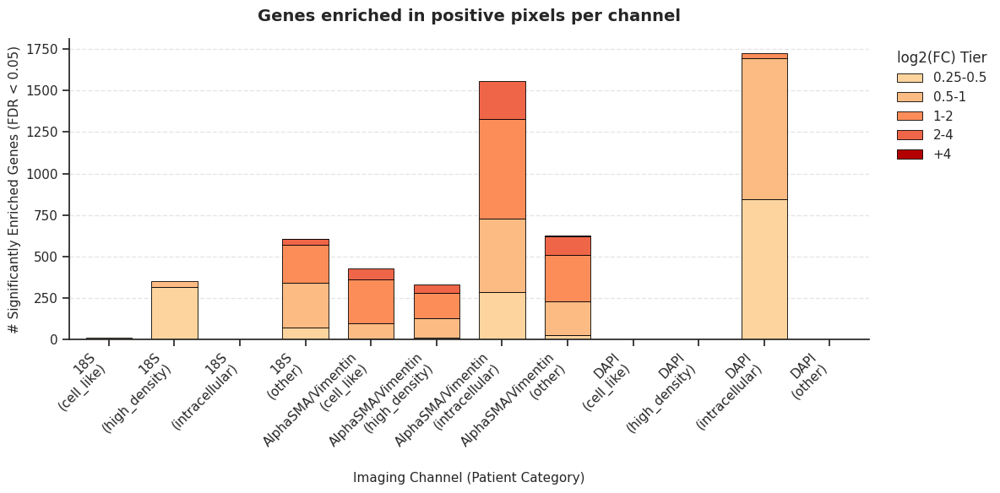

In [148]:
plot_significant_gene_counts(df_gene_category_enrichment)

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_gene_enrichment_dotplot(
    df: pd.DataFrame, 
    alpha: float = 0.05, 
    top_n_per_cond: int = 5
):
    """
    Plots a dot plot showing enrichment magnitude (color) and significance (size)
    for top enriched/depleted genes across categories and channels.
    """
    df = df.copy()
    
    # 1. Calculate transformation metrics
    # Small epsilon to avoid log2(0) or log10(0)
    df["log2_ER"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    df["neg_log10_padj"] = -np.log10(df["pvalue_adj"] + 1e-10)
    
    # Filter for significant rows to select our "interesting" genes
    sig_df = df[df["pvalue_adj"] < alpha]
    
    if sig_df.empty:
        print("No significant genes found at the specified alpha level.")
        return

    # 2. Smartly select top genes so the plot isn't overcrowded
    # Grab top N most enriched and top N most depleted per category/channel combination
    top_enriched = sig_df.groupby(["category", "channel"]) \
                         .apply(lambda x: x.nlargest(top_n_per_cond, "log2_ER"), include_groups=False)
    top_depleted = sig_df.groupby(["category", "channel"]) \
                         .apply(lambda x: x.nsmallest(top_n_per_cond, "log2_ER"), include_groups=False)
    
    genes_to_show = pd.concat([top_enriched, top_depleted])["gene"].unique()
    plot_data = df[df["gene"].isin(genes_to_show)].copy()
    
    # 3. Create the Faceted Plot
    sns.set_theme(style="whitegrid")
    g = sns.relplot(
        data=plot_data,
        x="channel",
        y="gene",
        hue="log2_ER",
        size="neg_log10_padj",
        col="category",
        palette="vlag",  # Diverging color map (blue = depleted, red = enriched)
        hue_norm=(-3, 3), # Clamp color scale for better visibility; adjust as needed
        sizes=(20, 200),  # Min and max size of dots
        kind="scatter",
        aspect=0.8,
        height=min(max(len(genes_to_show) * 0.25, 4), 12) # Dynamically scale height
    )
    
    # Titles and formatting
    g.set_titles(col_template="{col_name} Category")
    g.set_axis_labels("Imaging Channel", "Gene")
    g.tight_layout()
    
    # Adjust legends
    g._legend.set_title(None)
    for t in g._legend.texts:
        if "log2_ER" in t.get_text(): t.set_text("Log2 Enrichment")
        if "neg_log10_padj" in t.get_text(): t.set_text("-Log10 Adj P-val")
        
    plt.show()

def plot_gene_enrichment_heatmap(df: pd.DataFrame, alpha: float = 0.05, top_n_total: int = 40):
    """
    Plots a hierarchically clustered heatmap of Log2 Enrichment Ratios.
    Genes with similar behavior across channels/categories cluster together.
    """
    df = df.copy()
    df["log2_ER"] = np.log2(df["enrichment_ratio"].replace(0, np.nan))
    
    # Select genes based on variance or highest absolute enrichment to keep plot clean
    # Here we select genes that show the highest absolute deviation from 0
    df["abs_log2_ER"] = df["log2_ER"].abs()
    sig_df = df[df["pvalue_adj"] < alpha]
    
    top_genes = sig_df.groupby("gene")["abs_log2_ER"].max() \
                      .nlargest(top_n_total).index
                      
    df_filtered = df[df["gene"].isin(top_genes)]
    
    if df_filtered.empty:
        print("No significant data to display in heatmap.")
        return
        
    # Pivot data: rows = genes, columns = combination of channel and category
    pivot_df = df_filtered.pivot(
        index="gene", 
        columns=["category", "channel"], 
        values="log2_ER"
    ).fillna(0) # 0 means no enrichment change / expected random background
    
    # Plot the clustered heatmap
    g = sns.clustermap(
        pivot_df,
        cmap="vlag",       # Blue-white-red diverging palette
        center=0,          # Center colorbar at 0 (no enrichment change)
        linewidths=0.0,
        figsize=(12, 10),
        cbar_kws={'label': 'Log2 Enrichment Ratio\n(Red=Enriched, Blue=Depleted)'}
    )
    
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
    g.fig.suptitle(f"Hierarchical Clustering of Top {top_n_total} Significant Genes", y=1.02, fontsize=14, fontweight='bold')
    plt.show()

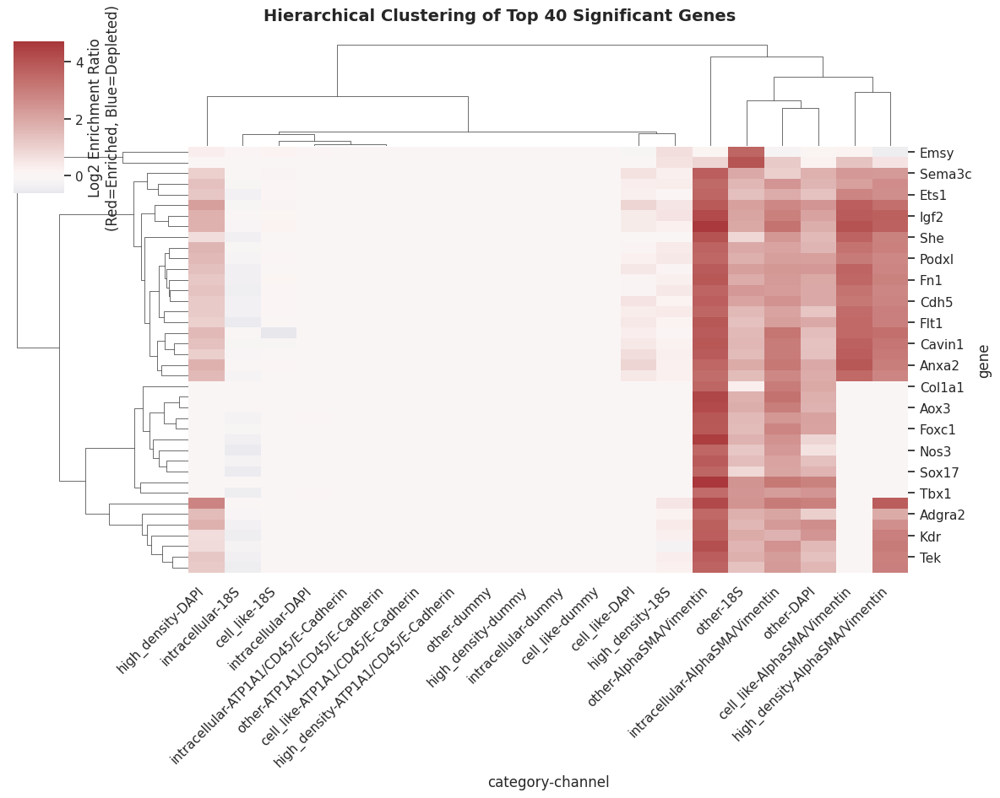

In [61]:
plot_gene_enrichment_heatmap(df_gene_category_enrichment)

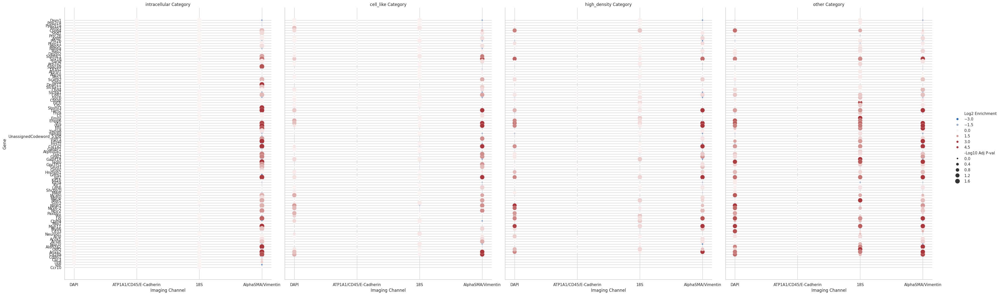

In [56]:
plot_gene_enrichment_dotplot(df_gene_category_enrichment)

In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_channel_volcano(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    top_x: int = 5,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    ncols: int = 3
):
    """
    Generates volcano plots faceted by transcript category for a single staining channel.
    Labels the top X most significant genes in each category subplot.
    """
    df = df_gene_category_enrichment.copy()
    
    # 1. Filter for the specific staining channel
    channel_df = df[df["channel"] == target_channel].copy()
    if channel_df.empty:
        print(f"No data found for channel: '{target_channel}'")
        return
        
    # 2. Compute transformations
    channel_df["logFC"] = np.log2(channel_df["enrichment_ratio"].replace(0, np.nan))
    # Small epsilon prevents log10(0) errors
    channel_df["neg_log10_padj"] = -np.log10(channel_df["pvalue_adj"] + 1e-10)
    
    # 3. Categorize points for coloring
    conditions = [
        (channel_df["pvalue_adj"] < alpha) & (channel_df["logFC"] >= logfc_thr),
        (channel_df["pvalue_adj"] < alpha) & (channel_df["logFC"] <= -logfc_thr)
    ]
    choices = ["Enriched", "Depleted"]
    channel_df["Significance"] = np.select(conditions, choices, default="Not Significant")
    
    color_dict = {
        "Enriched": "#ef6548",       # Crimson/Red
        "Depleted": "#1f77b4",       # Steel Blue
        "Not Significant": "darkgrey"
    }

    # 4. Set up dynamic subplot grid based on number of categories
    categories = sorted(channel_df["category"].unique())
    n_cats = len(categories)
    nrows = int(np.ceil(n_cats / ncols))
    
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 5 * nrows), sharey=True)
    axes = np.array(axes).flatten() # Flatten to 1D array for straightforward looping
    
    # 5. Plot each category
    for i, category in enumerate(categories):
        ax = axes[i]
        cat_df = channel_df[channel_df["category"] == category]
        
        # Draw background threshold lines
        ax.axhline(-np.log10(alpha), color="black", linestyle="--", alpha=0.3, linewidth=1)
        ax.axvline(logfc_thr, color="black", linestyle="--", alpha=0.3, linewidth=1)
        ax.axvline(-logfc_thr, color="black", linestyle="--", alpha=0.3, linewidth=1)
        
        # Scatter plot
        sns.scatterplot(
            data=cat_df,
            x="logFC",
            y="neg_log10_padj",
            hue="Significance",
            palette=color_dict,
            hue_order=["Enriched", "Depleted", "Not Significant"],
            alpha=0.7,
            edgecolor=None,
            s=25,
            ax=ax,
            legend=(i == 0) # Only show legend on the first subplot to save space
        )
        
        # 6. Find and label the top X most significant hits
        # Sorting by pvalue_adj guarantees we pull out the most confident spatial trends
        top_genes = cat_df.nsmallest(top_x, "pvalue_adj")
        
        texts = []
        for _, row in top_genes.iterrows():
            if pd.isna(row["logFC"]) or pd.isna(row["neg_log10_padj"]):
                continue
            texts.append(
                ax.text(
                    row["logFC"], 
                    row["neg_log10_padj"], 
                    row["gene"], 
                    fontsize=9, 
                    fontweight="semibold"
                )
            )
            
        # Optimize text positions if adjustText is available
        try:
            from adjustText import adjust_text
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))
        except ImportError:
            pass # Fall back to basic matplotlib layout coordinates if library is missing
            
        # Subplot Polish
        ax.set_title(f"Category: {category}", fontsize=12, fontweight="bold")
        ax.set_xlabel("$\log_2$ Enrichment Ratio")
        ax.set_ylabel("$-\log_{10}$ Adj P-value")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        
    # Hide any unused subplot tiles in your grid canvas
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    fig.suptitle(f"Volcano Plot Analysis for Channel: {target_channel}", fontsize=16, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

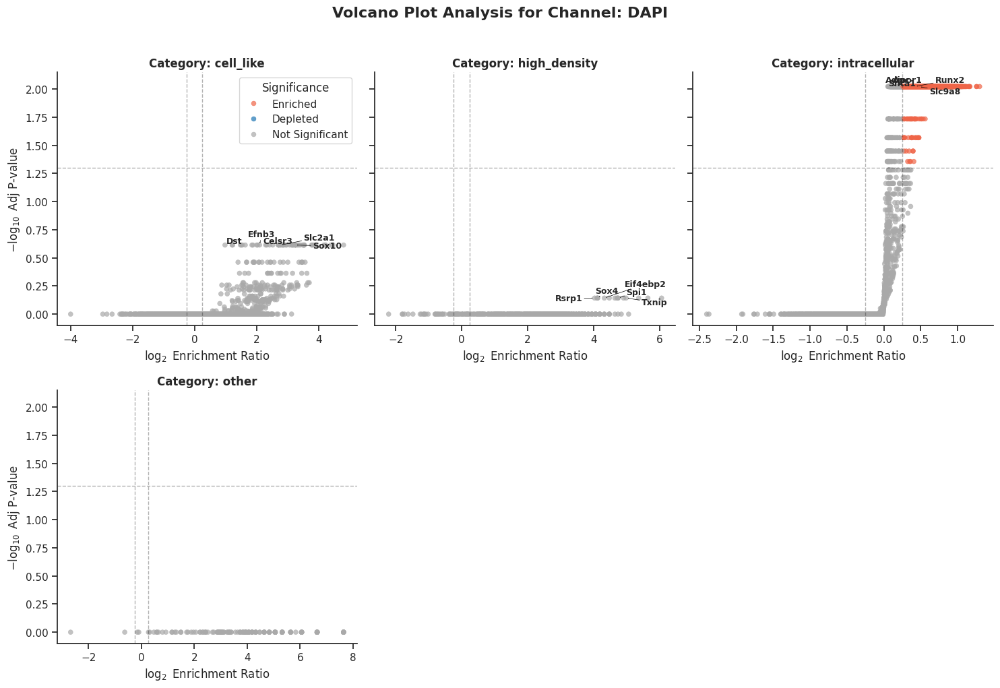

In [152]:
# Assuming your output data is in 'df_results' and you want to look at Insulin staining:
plot_channel_volcano(
    df_gene_category_enrichment=df_gene_category_enrichment, 
    target_channel="DAPI", 
    top_x=5
)

In [153]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def plot_channel_all_significant_dotplot(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
):
    """Plots a dot plot for ALL genes that are significant in at least one transcript

    category for the given channel, mapping significance to size and logFC to
    color across all categories.
    """
    df = df_gene_category_enrichment.copy()

    # 1. Filter for the target channel and compute metrics
    channel_df = df[df["channel"] == target_channel].copy()
    if channel_df.empty:
        print(f"No data found for channel: '{target_channel}'")
        return

    channel_df["logFC"] = np.log2(
        channel_df["enrichment_ratio"].replace(0, np.nan)
    )
    channel_df["neg_log10_padj"] = -np.log10(
        channel_df["pvalue_adj"] + 1e-10
    )

    # 2. Identify the pool of genes significant in AT LEAST ONE category
    sig_mask = (channel_df["pvalue_adj"] < alpha) & (
        channel_df["logFC"].abs() >= logfc_thr
    )
    significant_genes = channel_df[sig_mask]["gene"].unique()

    if len(significant_genes) == 0:
        print(
            f"No significant genes found for channel '{target_channel}' at FDR < {alpha}."
        )
        return

    # Filter data to only include this significant gene pool across all categories
    plot_data = channel_df[channel_df["gene"].isin(significant_genes)].copy()

    # 3. Sort genes on the Y-axis by their maximum enrichment to make patterns readable
    gene_order = (
        plot_data.groupby("gene")["logFC"].max().sort_values(ascending=False).index
    )

    # FIXED: Safely apply the categorical ordering via the `.cat` accessor
    plot_data["gene"] = pd.Categorical(
        plot_data["gene"], categories=gene_order, ordered=True
    )

    # 4. Plotting Setup
    sns.set_theme(style="whitegrid")

    # Dynamically scale height based on the number of significant genes
    fig_height = max(len(significant_genes) * 0.22, 4)

    fig, ax = plt.subplots(figsize=(5, fig_height))

    # Create scatter plot mapping Categories to X-axis and Genes to Y-axis
    scatter = ax.scatter(
        x=plot_data["category"],
        y=plot_data["gene"],
        c=plot_data["logFC"],
        s=plot_data["neg_log10_padj"] * 60,  # Scale factor for visible dot sizes
        cmap="vlag",  # Diverging blue-white-red palette
        vmin=-4,
        vmax=4,  # Adjust color bounds to fit data profile
        edgecolors="black",
        linewidths=0.1,
        zorder=3,
    )

    # Clean borders and axis aesthetics
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(True, linestyle="--", alpha=0.5, zorder=0)

    ax.set_title(
        f"Significant Gene Dynamics for {target_channel}\nAcross Transcript Categories",
        fontsize=13,
        fontweight="bold",
        pad=15,
    )
    ax.set_xlabel("Transcript Category", fontsize=11, labelpad=10)
    ax.set_ylabel("Genes", fontsize=11)

    # 5. Dual Legend Construction (Color and Size)
    cbar = fig.colorbar(
        scatter, ax=ax, pad=0.05, shrink=0.5, orientation="vertical"
    )
    cbar.set_label("$\log_2$ Enrichment Ratio", fontsize=10)

    # Add size legend manually
    handles, labels = [], []
    for pval in [0.05, 0.01, 0.001, 1e-5]:
        neg_log = -np.log10(pval)
        handles.append(
            plt.Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                markerfacecolor="darkgrey",
                markeredgecolor="k",
                markersize=np.sqrt(neg_log * 15),
            )
        )
        labels.append(f"p={pval}")

    ax.legend(
        handles,
        labels,
        title="$P$-value Significance",
        bbox_to_anchor=(1.35, 1),
        loc="upper left",
        frameon=False,
    )

    plt.tight_layout()
    plt.show()

In [154]:
plot_channel_all_significant_dotplot(df_gene_category_enrichment,target_channel='DAPI',logfc_thr=2)

No significant genes found for channel 'DAPI' at FDR < 0.05.


## We plot channel comparisons

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

def plot_channel_vs_channel_logfc(
    df_gene_category_enrichment: pd.DataFrame,
    target_category: str,
    channel_x: str,
    channel_y: str,
    df_summary: pd.DataFrame = None,  # Pass your df_summary table here!
    pct_x: float = None,              # Manual override for channel X percentage
    pct_y: float = None,              # Manual override for channel Y percentage
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 5,
    saving_path: str = None,
):
    """Plots logFC of channel_x vs channel_y for a given transcript category.

    Automatically extracts channel positive pixel percentages from df_summary
    and embeds them directly into the X and Y axis labels.
    """
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    df = df_gene_category_enrichment.copy()

    # 1. Filter for the specific transcript category
    cat_df = df[df["category"] == target_category].copy()
    if cat_df.empty:
        print(f"No data found for transcript category: '{target_category}'")
        return

    # Calculate logFC upfront
    cat_df["logFC"] = np.log2(cat_df["enrichment_ratio"].replace(0, np.nan))

    # 2. Extract channel pixel percentages dynamically from df_summary
    val_x, val_y = pct_x, pct_y

    if df_summary is not None and (val_x is None or val_y is None):
        # Look up based on the column structures produced by analyze_channels_and_get_thresholds
        ch_col = "Channel Name" if "Channel Name" in df_summary.columns else df_summary.columns[0]
        pct_col = [c for c in df_summary.columns if "Positive Pixels" in c or "pct" in c.lower()]
        
        if pct_col:
            pct_col_name = pct_col[0]
            try:
                if val_x is None:
                    val_x = df_summary[df_summary[ch_col] == channel_x][pct_col_name].iloc[0]
                if val_y is None:
                    val_y = df_summary[df_summary[ch_col] == channel_y][pct_col_name].iloc[0]
            except IndexError:
                pass

    # Build final label texts for the axes layout
    label_x_text = f"{channel_x} ({val_x:.1f}%)" if val_x is not None else f"{channel_x}"
    label_y_text = f"{channel_y} ({val_y:.1f}%)" if val_y is not None else f"{channel_y}"

    # 3. Separate datasets for Channel X and Channel Y, then merge on Gene
    df_x = cat_df[cat_df["channel"] == channel_x][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_x", "pvalue_adj": "padj_x"})
    df_y = cat_df[cat_df["channel"] == channel_y][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_y", "pvalue_adj": "padj_y"})

    merged = pd.merge(df_x, df_y, on="gene", how="inner")

    if merged.empty:
        print(f"No overlapping genes found between {channel_x} and {channel_y}.")
        return

    # 4. Apply Dual-Gating Filters for Significance (FDR AND logFC magnitude)
    sig_x = (merged["padj_x"] < alpha) & (merged["logFC_x"].abs() >= logfc_thr)
    sig_y = (merged["padj_y"] < alpha) & (merged["logFC_y"].abs() >= logfc_thr)

    conditions = [sig_x & sig_y, sig_x & ~sig_y, ~sig_x & sig_y]
    choices = ["Both", f"{channel_x} Only", f"{channel_y} Only"]
    merged["Significance_Type"] = np.select(
        conditions, choices, default="Not Significant"
    )
    merged["is_significant"] = sig_x | sig_y

    # 5. Plotting Setup
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(7, 7))

    min_val = min(merged["logFC_x"].min(), merged["logFC_y"].min()) - 0.5
    max_val = max(merged["logFC_x"].max(), merged["logFC_y"].max()) + 0.5
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        alpha=0.4,
        label="Equal Enrichment ($y=x$)",
    )

    # Threshold indicator lines
    ax.axhline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axhline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axhline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)

    color_dict = {
        "Both": "#6a3d9a",
        f"{channel_x} Only": "#1f77b4",
        f"{channel_y} Only": "#ff7f0e",
        "Not Significant": "#e0e0e0",
    }

    sns.scatterplot(
        data=merged,
        x="logFC_x",
        y="logFC_y",
        hue="Significance_Type",
        palette=color_dict,
        hue_order=["Both", f"{channel_x} Only", f"{channel_y} Only", "Not Significant"],
        alpha=0.9,
        edgecolor="w",
        linewidth=0.01,
        s=10,
        ax=ax,
    )

    # 6. Labeling outliers
    sig_pool = merged[merged["is_significant"]].copy()
    if not sig_pool.empty:
        top_x = sig_pool.loc[sig_pool["logFC_x"].abs().nlargest(top_n_labels).index]
        top_y = sig_pool.loc[sig_pool["logFC_y"].abs().nlargest(top_n_labels).index]
        labels_df = pd.concat([top_x, top_y]).drop_duplicates(subset=["gene"])

        texts = []
        for _, row in labels_df.iterrows():
            if pd.isna(row["logFC_x"]) or pd.isna(row["logFC_y"]):
                continue
            texts.append(
                ax.text(
                    row["logFC_x"],
                    row["logFC_y"],
                    row["gene"],
                    fontsize=9,
                    fontweight="semibold",
                )
            )

        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5),
            )
        except ImportError:
            pass

    # Styling and Polish
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Spatial Localization Preference ({target_category})\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=11,
        fontweight="bold",
        pad=12,
    )
    ax.set_xlabel(f"$\log_2$ Enrichment in {label_x_text}", fontsize=11)
    ax.set_ylabel(f"$\log_2$ Enrichment in {label_y_text}", fontsize=11)

    plt.legend(frameon=False, loc="upper left")
    plt.tight_layout()

    # 7. Dynamically Construct Sanitized Name and Save File
    if saving_path is not None:
        clean_cat = target_category.replace("/", "_").replace(" ", "_")
        clean_x = channel_x.replace("/", "_")
        clean_y = channel_y.replace("/", "_")

        filename = f"{clean_x}_vs_{clean_y}_{clean_cat}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_vs_AlphaSMA_Vimentin_intracellular.pdf


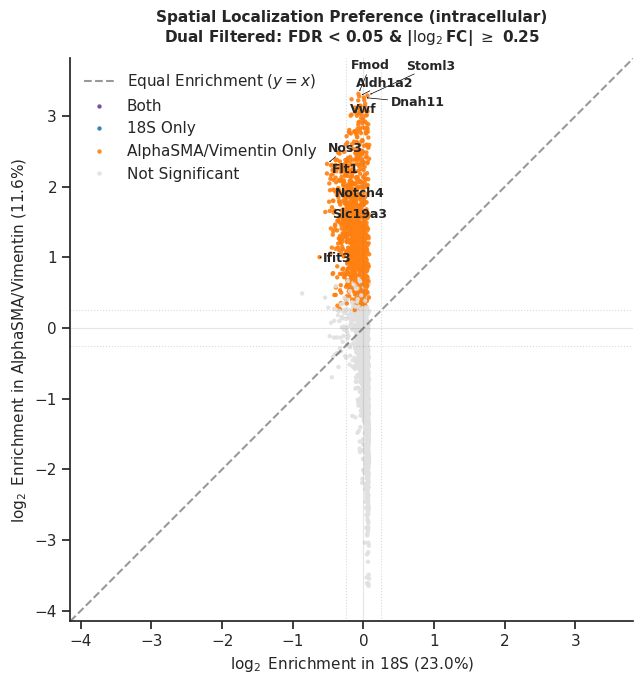

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_vs_AlphaSMA_Vimentin_cell_like.pdf


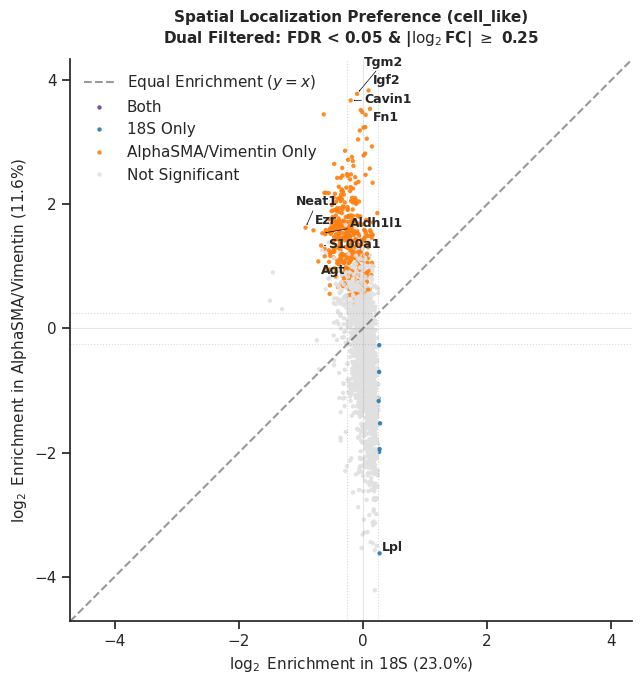

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_vs_AlphaSMA_Vimentin_high_density.pdf


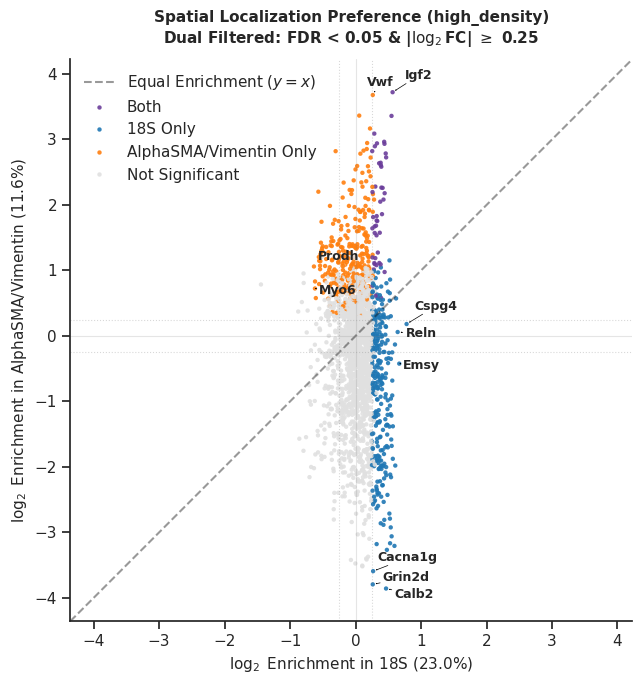

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_vs_AlphaSMA_Vimentin_other.pdf


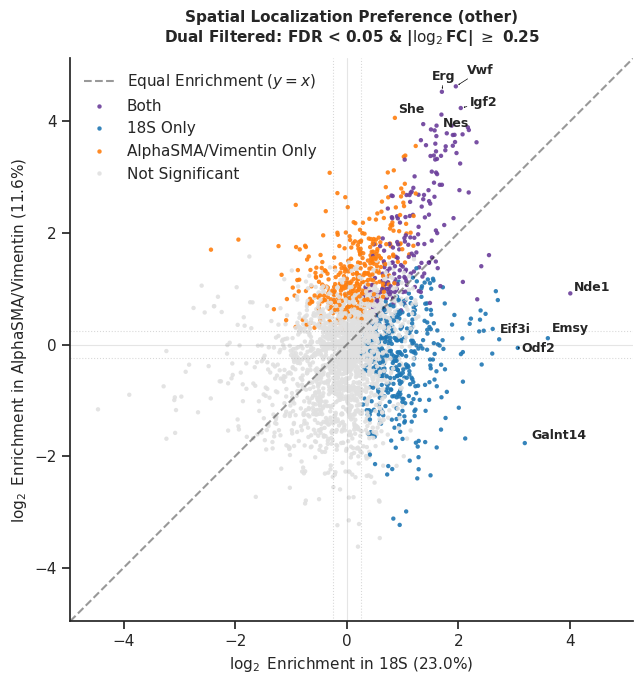

In [162]:
for cat in df_gene_category_enrichment['category'].unique():
    plot_channel_vs_channel_logfc(
        df_gene_category_enrichment=df_gene_category_enrichment,
        df_summary=df_summary,    
        target_category=cat,
        channel_x="18S",
        channel_y="AlphaSMA/Vimentin",
        top_n_labels=5,saving_path=saving_path
    )

In [170]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns


def plot_category_vs_category_logfc(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    category_x: str,
    category_y: str,
    df_summary: pd.DataFrame = None,  # Total channel pixel coverage summary
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 5,
    saving_path: str = None,
):
    """Plots logFC of category_x vs category_y for a given single channel.

    Dynamically isolates the exact observed % of positive pixels unique to each 
    transcript category group and explicitly appends them to the X and Y axis labels.
    """
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42

    df = df_gene_category_enrichment.copy()

    # 1. Filter dataset for the chosen channel
    ch_df = df[df["channel"] == target_channel].copy()
    if ch_df.empty:
        print(f"No data found for channel: '{target_channel}'")
        return

    # Calculate logFC upfront
    ch_df["logFC"] = np.log2(ch_df["enrichment_ratio"].replace(0, np.nan))

    # 2. Extract Overall Channel positive pixel percentage from df_summary
    val_pct = None
    if df_summary is not None:
        ch_col = "Channel Name" if "Channel Name" in df_summary.columns else df_summary.columns[0]
        pct_col = [c for c in df_summary.columns if "Positive Pixels" in c or "pct" in c.lower()]
        if pct_col:
            pct_col_name = pct_col[0]
            try:
                val_pct = df_summary[df_summary[ch_col] == target_channel][pct_col_name].iloc[0]
            except IndexError:
                pass

    ch_label = f"{target_channel} ({val_pct:.1f}%)" if val_pct is not None else f"{target_channel}"

    # 3. FIXED: Extract the unique Category-Specific Positivity Percentages
    pct_cat_x = None
    pct_cat_y = None
    
    try:
        pct_cat_x = ch_df[ch_df["category"] == category_x]["pct_positive_observed"].median()
        pct_cat_y = ch_df[ch_df["category"] == category_y]["pct_positive_observed"].median()
    except (KeyError, IndexError):
        pass

    # Build axis labels with the category-specific % embedded directly
    label_x_text = f"'{category_x}' ({pct_cat_x:.1f}%)" if pct_cat_x is not None and not np.isnan(pct_cat_x) else f"'{category_x}'"
    label_y_text = f"'{category_y}' ({pct_cat_y:.1f}%)" if pct_cat_y is not None and not np.isnan(pct_cat_y) else f"'{category_y}'"

    # 4. Separate datasets for Category X and Category Y, then merge on Gene
    df_x = ch_df[ch_df["category"] == category_x][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_x", "pvalue_adj": "padj_x"})
    
    df_y = ch_df[ch_df["category"] == category_y][
        ["gene", "logFC", "pvalue_adj"]
    ].rename(columns={"logFC": "logFC_y", "pvalue_adj": "padj_y"})

    merged = pd.merge(df_x, df_y, on="gene", how="inner")

    if merged.empty:
        print(f"No overlapping genes found between category '{category_x}' and '{category_y}'.")
        return

    # 5. Apply Dual-Gating Filters for Significance (FDR AND logFC magnitude)
    sig_x = (merged["padj_x"] < alpha) & (merged["logFC_x"].abs() >= logfc_thr)
    sig_y = (merged["padj_y"] < alpha) & (merged["logFC_y"].abs() >= logfc_thr)

    conditions = [sig_x & sig_y, sig_x & ~sig_y, ~sig_x & sig_y]
    choices = ["Both", f"{category_x} Only", f"{category_y} Only"]
    merged["Significance_Type"] = np.select(
        conditions, choices, default="Not Significant"
    )
    merged["is_significant"] = sig_x | sig_y

    # 6. Plotting Setup
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(7, 7))

    min_val = min(merged["logFC_x"].min(), merged["logFC_y"].min()) - 0.5
    max_val = max(merged["logFC_x"].max(), merged["logFC_y"].max()) + 0.5
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--",
        alpha=0.4,
        label="Equal Enrichment ($y=x$)",
    )

    # Threshold indicator lines
    ax.axhline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axvline(0, color="grey", linestyle="-", alpha=0.2, linewidth=0.8)
    ax.axhline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axhline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)
    ax.axvline(-logfc_thr, color="grey", linestyle=":", alpha=0.3, linewidth=0.8)

    color_dict = {
        "Both": "#41bda5",
        f"{category_x} Only": "#ed2474",
        f"{category_y} Only": "#123755",
        "Not Significant": "#e0e0e0",
    }

    sns.scatterplot(
        data=merged,
        x="logFC_x",
        y="logFC_y",
        hue="Significance_Type",
        palette=color_dict,
        hue_order=["Both", f"{category_x} Only", f"{category_y} Only", "Not Significant"],
        alpha=0.9,
        edgecolor="w",
        linewidth=0.01,
        s=10,
        ax=ax,
    )

    # 7. Labeling outliers
    sig_pool = merged[merged["is_significant"]].copy()
    if not sig_pool.empty:
        top_x = sig_pool.loc[sig_pool["logFC_x"].abs().nlargest(top_n_labels).index]
        top_y = sig_pool.loc[sig_pool["logFC_y"].abs().nlargest(top_n_labels).index]
        labels_df = pd.concat([top_x, top_y]).drop_duplicates(subset=["gene"])

        texts = []
        for _, row in labels_df.iterrows():
            if pd.isna(row["logFC_x"]) or pd.isna(row["logFC_y"]):
                continue
            texts.append(
                ax.text(
                    row["logFC_x"],
                    row["logFC_y"],
                    row["gene"],
                    fontsize=9,
                    fontweight="semibold",
                )
            )

        try:
            from adjustText import adjust_text

            adjust_text(
                texts,
                ax=ax,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5),
            )
        except ImportError:
            pass

    # Styling and Polish
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_title(
        f"Transcript Category Comparison ({ch_label})\nDual Filtered: FDR < {alpha} & |$\log_2$FC| $\geq$ {logfc_thr}",
        fontsize=11,
        fontweight="bold",
        pad=12,
    )
    
    # Axis labels displaying the unique category positivity rates
    ax.set_xlabel(f"$\log_2$ Enrichment in {label_x_text}", fontsize=11)
    ax.set_ylabel(f"$\log_2$ Enrichment in {label_y_text}", fontsize=11)

    plt.legend(frameon=False, loc="upper left")
    plt.tight_layout()

    # 8. Dynamically Construct Sanitized Name and Save File
    if saving_path is not None:
        clean_ch = target_channel.replace("/", "_").replace(" ", "_")
        clean_cat_x = category_x.replace("/", "_").replace(" ", "_")
        clean_cat_y = category_y.replace("/", "_").replace(" ", "_")

        filename = f"{clean_ch}_{clean_cat_x}_vs_{clean_cat_y}.pdf"
        full_output_path = os.path.join(saving_path, filename)

        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported vector plot to: {full_output_path}")

    plt.show()

Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_intracellular_vs_other.pdf


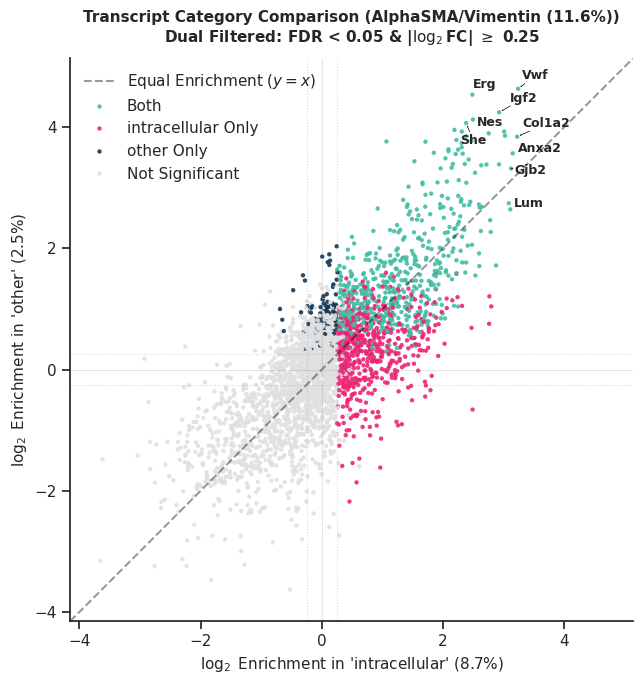

In [171]:
plot_category_vs_category_logfc(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="AlphaSMA/Vimentin",
    category_x="intracellular",
    category_y="other",
    saving_path=saving_path
)

In [172]:
import itertools
from pathlib import Path


def plot_all_category_combinations(
    df_gene_category_enrichment: pd.DataFrame,
    target_channel: str,
    df_summary: pd.DataFrame = None,
    alpha: float = 0.05,
    logfc_thr: float = 0.25,
    top_n_labels: int = 5,
    saving_path: str = None,
):
    """Finds all unique categories in the dataset and generates the category vs

    category logFC scatter plots for all possible non-redundant pairs.
    """
    # 1. Extract unique categories present for this channel
    ch_mask = df_gene_category_enrichment["channel"] == target_channel
    available_categories = (
        df_gene_category_enrichment[ch_mask]["category"].unique().tolist()
    )

    # Clean out any null/nan values if they exist
    available_categories = [
        cat for cat in available_categories if pd.notna(cat)
    ]

    if len(available_categories) < 2:
        print(
            f"Not enough unique categories found for channel '{target_channel}' to make a comparison plot."
        )
        print(f"Found categories: {available_categories}")
        return

    print(
        f"Found {len(available_categories)} categories for '{target_channel}': {available_categories}"
    )

    # 2. Generate all unique combinations of pairs (n over 2)
    category_pairs = list(itertools.combinations(available_categories, 2))
    print(f"--> Generating {len(category_pairs)} unique comparison plots...\n")

    # 3. Loop through and run your plotting engine
    for cat_x, cat_y in category_pairs:
        print(f"Running plot: Category '{cat_x}' vs Category '{cat_y}'")
        plot_category_vs_category_logfc(
            df_gene_category_enrichment=df_gene_category_enrichment,
            target_channel=target_channel,
            category_x=cat_x,
            category_y=cat_y,
            df_summary=df_summary,
            alpha=alpha,
            logfc_thr=logfc_thr,
            top_n_labels=top_n_labels,
            saving_path=saving_path,
        )

Found 4 categories for 'AlphaSMA/Vimentin': ['intracellular', 'cell_like', 'high_density', 'other']
--> Generating 6 unique comparison plots...

Running plot: Category 'intracellular' vs Category 'cell_like'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_intracellular_vs_cell_like.pdf


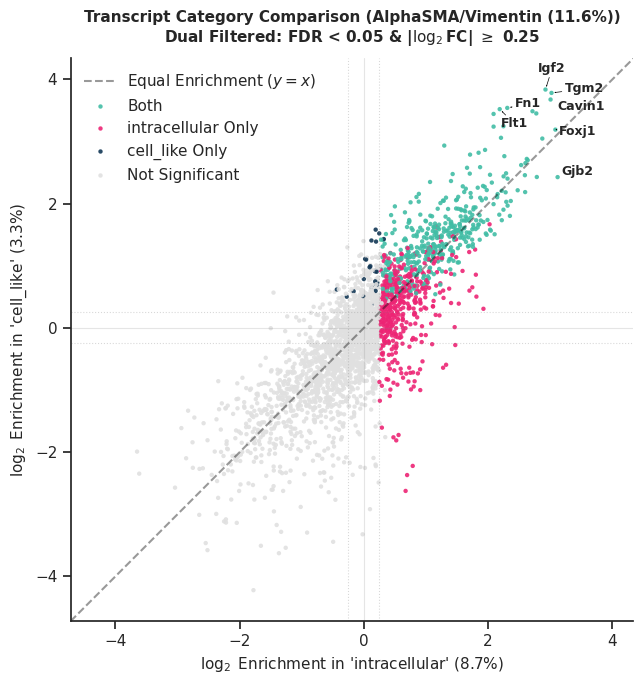

Running plot: Category 'intracellular' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_intracellular_vs_high_density.pdf


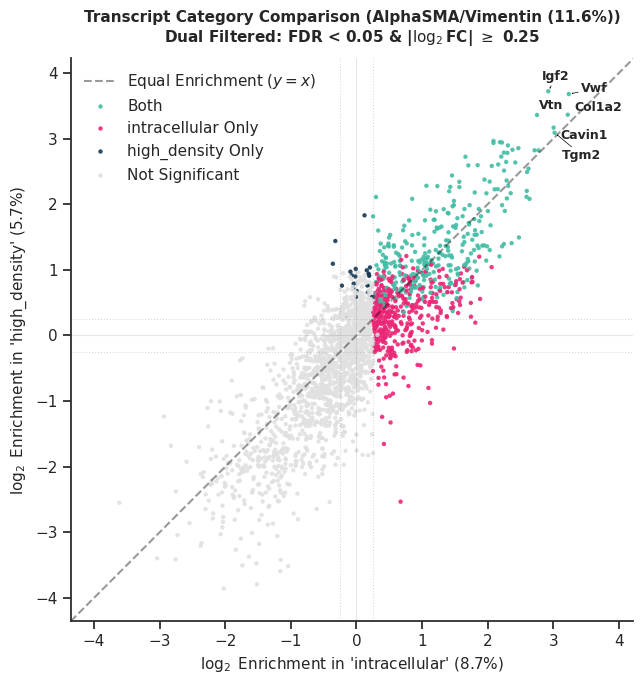

Running plot: Category 'intracellular' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_intracellular_vs_other.pdf


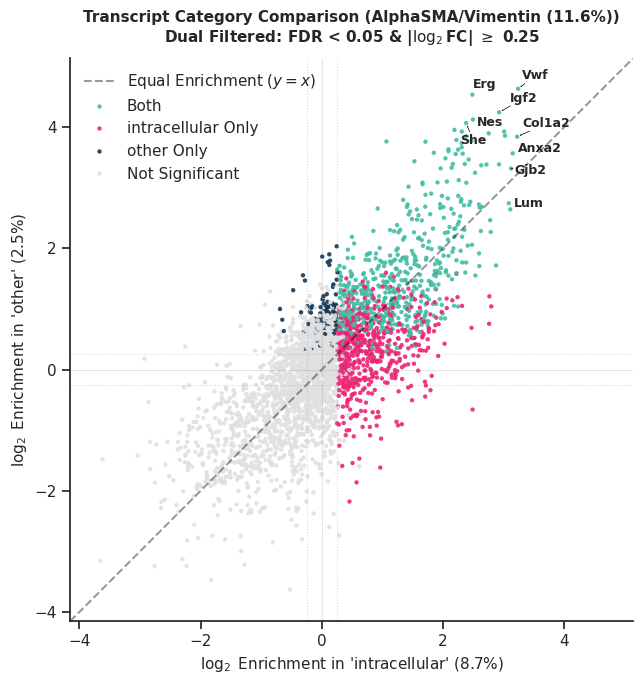

Running plot: Category 'cell_like' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_cell_like_vs_high_density.pdf


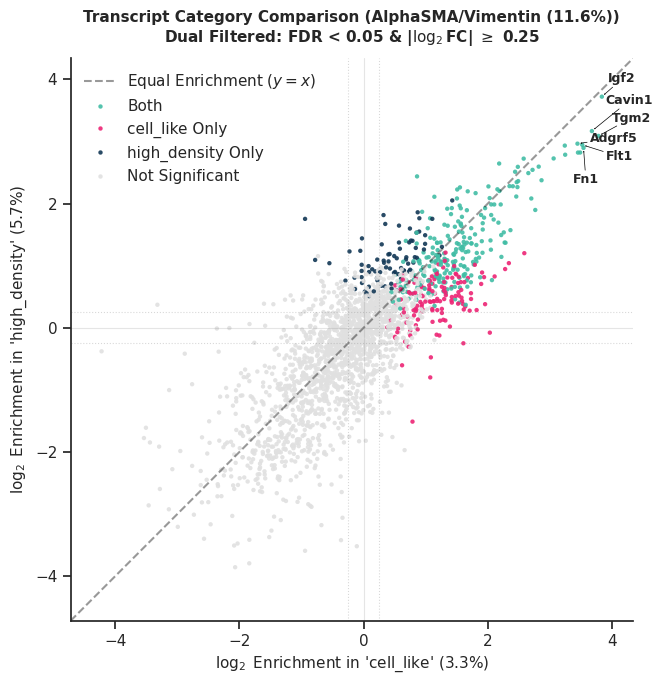

Running plot: Category 'cell_like' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_cell_like_vs_other.pdf


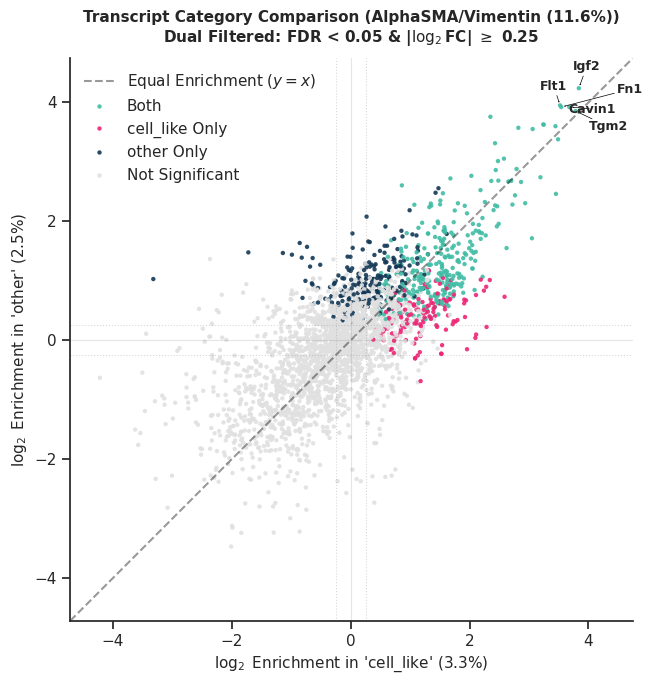

Running plot: Category 'high_density' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/AlphaSMA_Vimentin_high_density_vs_other.pdf


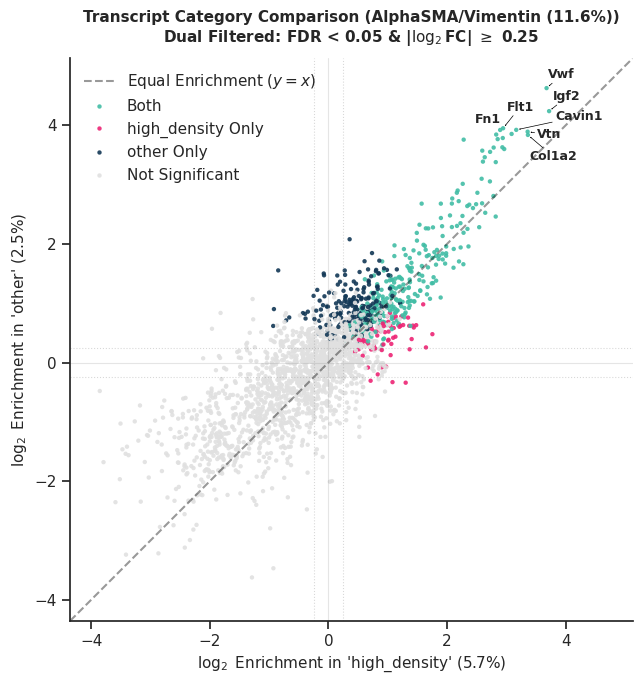

In [173]:
plot_all_category_combinations(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="AlphaSMA/Vimentin",
    logfc_thr=0.25,
    alpha=0.05,
    top_n_labels=5,
    saving_path=saving_path
)

Found 4 categories for '18S': ['intracellular', 'cell_like', 'high_density', 'other']
--> Generating 6 unique comparison plots...

Running plot: Category 'intracellular' vs Category 'cell_like'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_intracellular_vs_cell_like.pdf


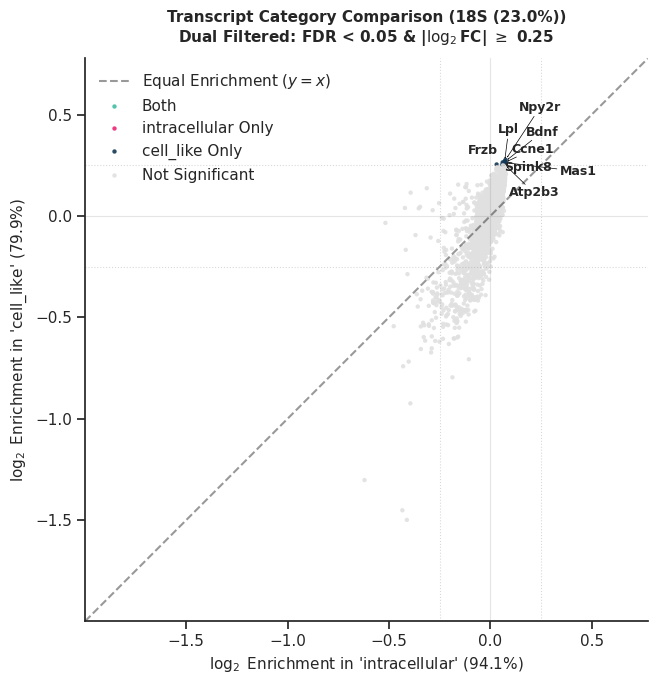

Running plot: Category 'intracellular' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_intracellular_vs_high_density.pdf


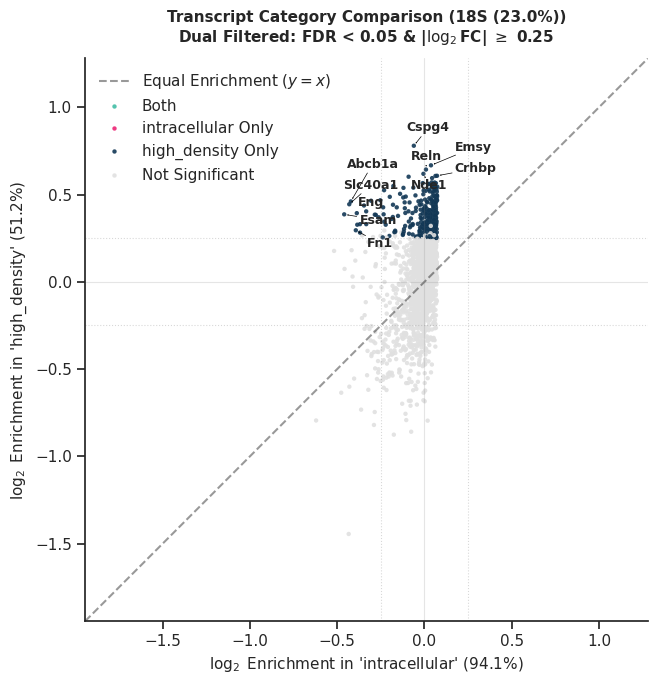

Running plot: Category 'intracellular' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_intracellular_vs_other.pdf


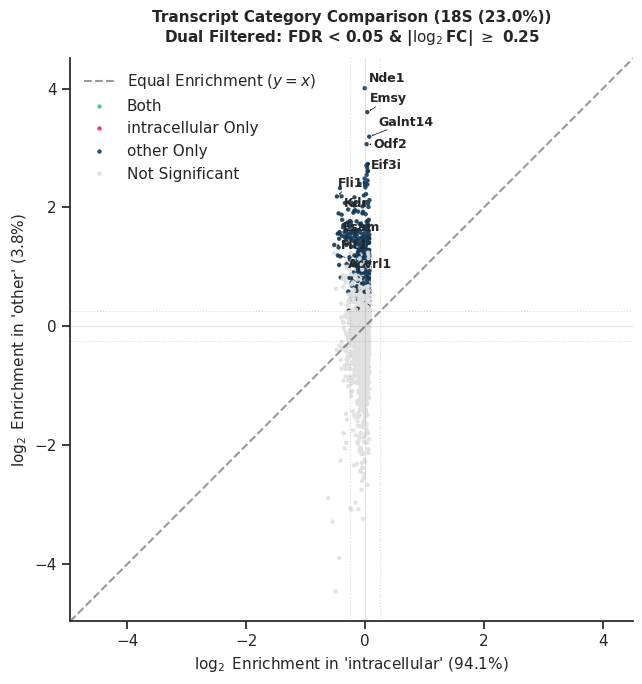

Running plot: Category 'cell_like' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_cell_like_vs_high_density.pdf


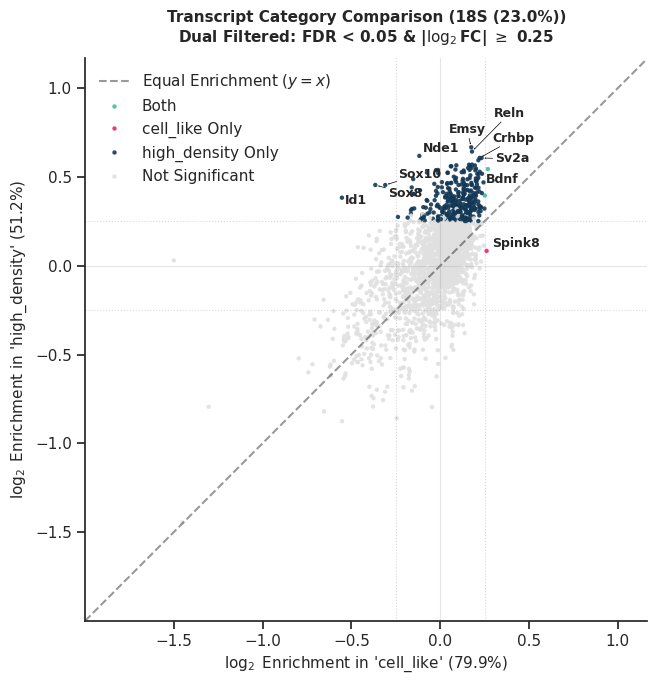

Running plot: Category 'cell_like' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_cell_like_vs_other.pdf


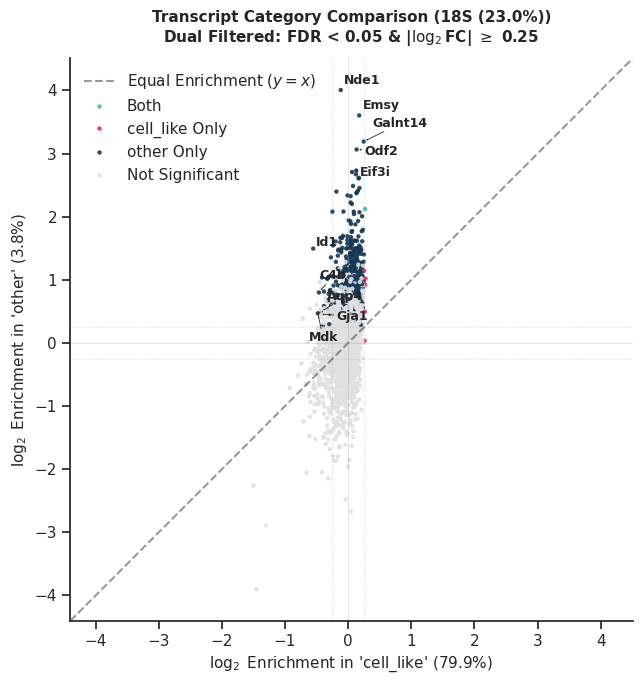

Running plot: Category 'high_density' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/18S_high_density_vs_other.pdf


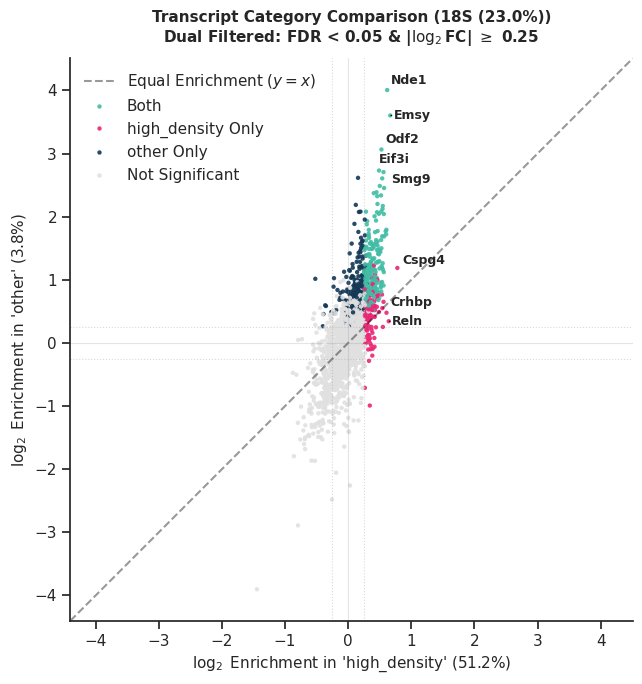

In [174]:
plot_all_category_combinations(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="18S",
    logfc_thr=0.25,
    alpha=0.05,
    top_n_labels=5,
    saving_path=saving_path
)

Found 4 categories for 'DAPI': ['intracellular', 'cell_like', 'high_density', 'other']
--> Generating 6 unique comparison plots...

Running plot: Category 'intracellular' vs Category 'cell_like'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_intracellular_vs_cell_like.pdf


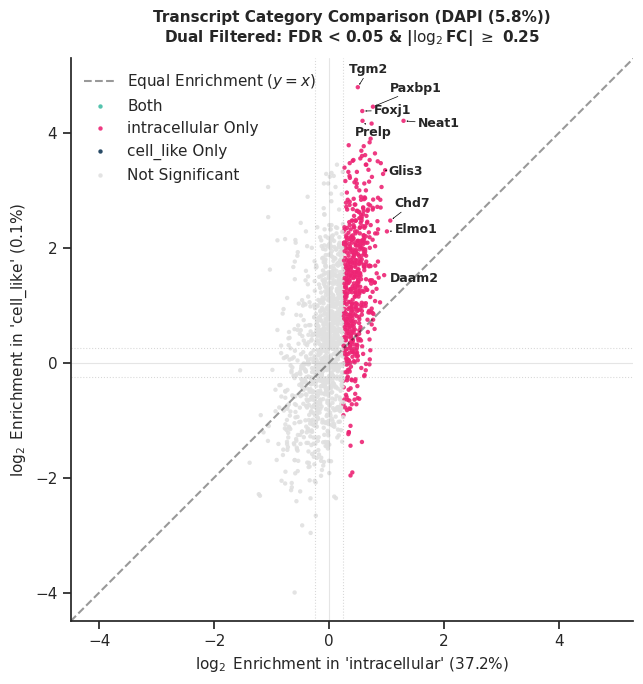

Running plot: Category 'intracellular' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_intracellular_vs_high_density.pdf


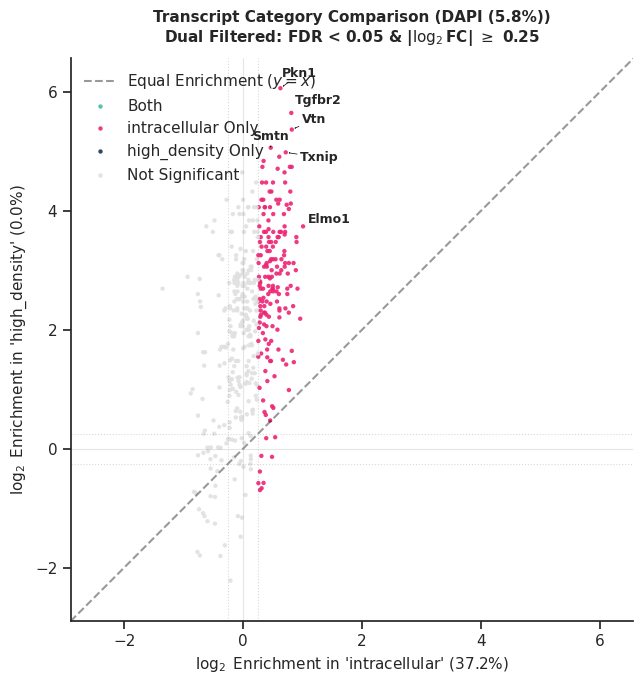

Running plot: Category 'intracellular' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_intracellular_vs_other.pdf


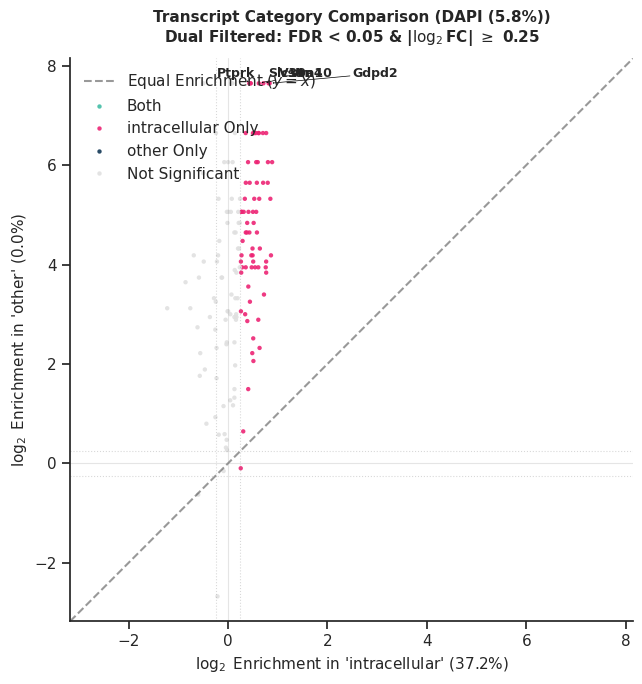

Running plot: Category 'cell_like' vs Category 'high_density'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_cell_like_vs_high_density.pdf


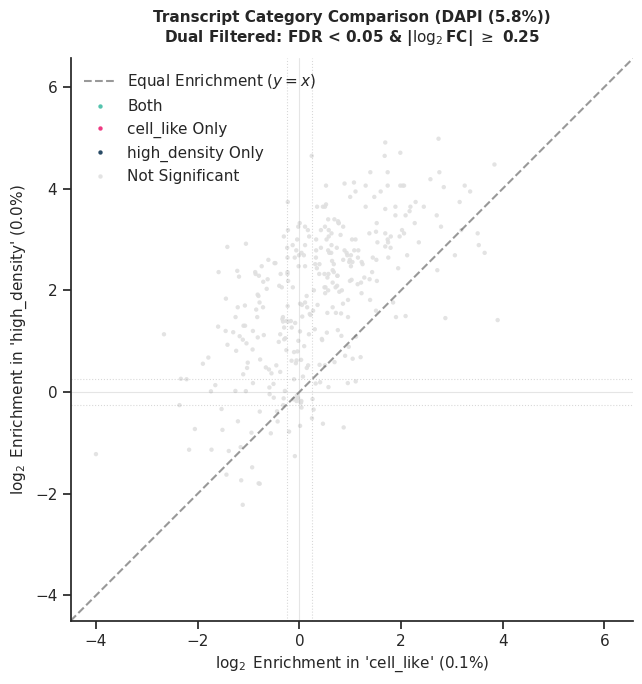

Running plot: Category 'cell_like' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_cell_like_vs_other.pdf


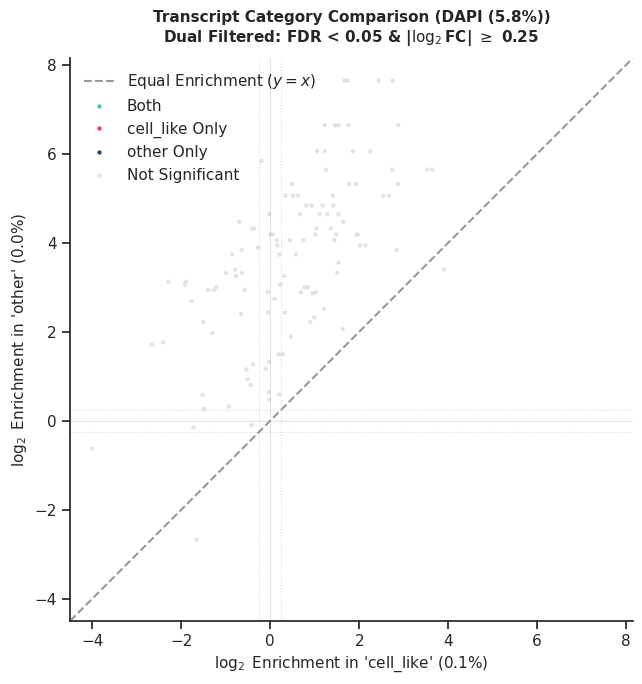

Running plot: Category 'high_density' vs Category 'other'
Successfully exported vector plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/DAPI_high_density_vs_other.pdf


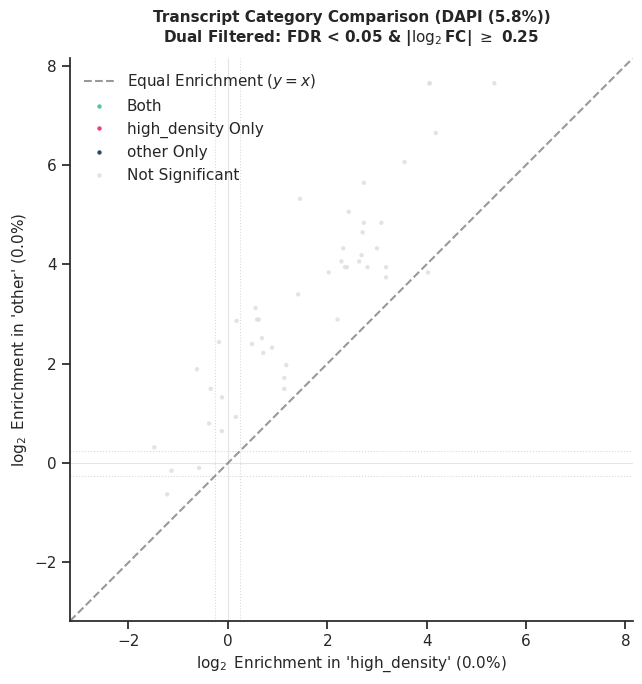

In [175]:
plot_all_category_combinations(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="DAPI",
    logfc_thr=0.25,
    alpha=0.05,
    top_n_labels=5,
    saving_path=saving_path
)

In [ ]:
plot_all_category_combinations(
    df_gene_category_enrichment=df_gene_category_enrichment,
    df_summary=df_summary,
    target_channel="DAPI",
    logfc_thr=0.25,
    alpha=0.05,
    top_n_labels=5,
    saving_path=saving_path
)

In [178]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

def plot_staining_positivity_by_type(
    trans_df: pd.DataFrame,
    channel_names: list[str],
    category_col: str = "transcript_category",
    saving_path: str = None,
):
    """
    Generates a sorted, grouped barplot showing the percentage of transcripts 
    landing on positive pixels for each staining, broken down by transcript category.
    """
    mpl.rcParams["pdf.fonttype"] = 42
    mpl.rcParams["ps.fonttype"] = 42
    
    # 1. Compile the percentage of positive transcripts per category per channel
    plot_data = []
    for channel in channel_names:
        pos_col = f"positive_{channel}"
        if pos_col in trans_df.columns:
            # Calculate the mean (fraction) and convert to percentage for each category
            pcts = trans_df.groupby(category_col, observed=False)[pos_col].mean() * 100
            for cat, val in pcts.items():
                plot_data.append({
                    "Staining": channel,
                    "Transcript Type": cat,
                    "% Transcripts on Positive Pixels": val
                })
                
    df_plot = pd.DataFrame(plot_data)
    if df_plot.empty:
        print("No matching channel positivity columns found in the dataframe.")
        return

    # 2. Sort the Stainings (X-axis) by their total average positivity to ensure a clean layout
    staining_order = (
        df_plot.groupby("Staining")["% Transcripts on Positive Pixels"]
        .mean()
        .sort_values(ascending=False)
        .index
    )

    # 3. Map your exact requested hex colors to the transcript categories
    color_palette = {
        "intracellular": "#41bda5",
        "cell_like": "#ed2474",
        "high_density": "#9dcb3b",
        "other": "#123755"
    }

    # 4. Plotting Setup
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(6, 6))

    sns.barplot(
        data=df_plot,
        x="Staining",
        y="% Transcripts on Positive Pixels",
        hue="Transcript Type",
        order=staining_order,
        hue_order=["intracellular", "cell_like", "high_density", "other"],
        palette=color_palette,
        edgecolor="black",
        linewidth=0.1,
        ax=ax
    )

    # Aesthetics and Styling
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylabel("% Transcripts on Positive Pixels", fontsize=11, fontweight="bold")
    ax.set_xlabel("Staining Channel", fontsize=11, fontweight="bold")
    ax.set_title("Transcript Pixel Positivity Rate across Staining Channels", fontsize=13, fontweight="bold", pad=15)
    
    # Rotate labels if channel names are long to prevent overlapping
    plt.xticks(rotation=45, ha="right")
    
    # Place legend neatly outside or on a clear spot
    ax.legend(title="Transcript Type", frameon=False, loc="upper right")
    
    plt.tight_layout()

    # 5. Save figure if a path is specified
    if saving_path is not None:
        os.makedirs(saving_path, exist_ok=True)
        full_output_path = os.path.join(saving_path, "staining_positivity_by_transcript_type.pdf")
        plt.savefig(full_output_path, format="pdf", bbox_inches="tight", dpi=300)
        print(f"Successfully exported barplot to: {full_output_path}")

    plt.show()

Successfully exported barplot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/staining_positivity_by_transcript_type.pdf


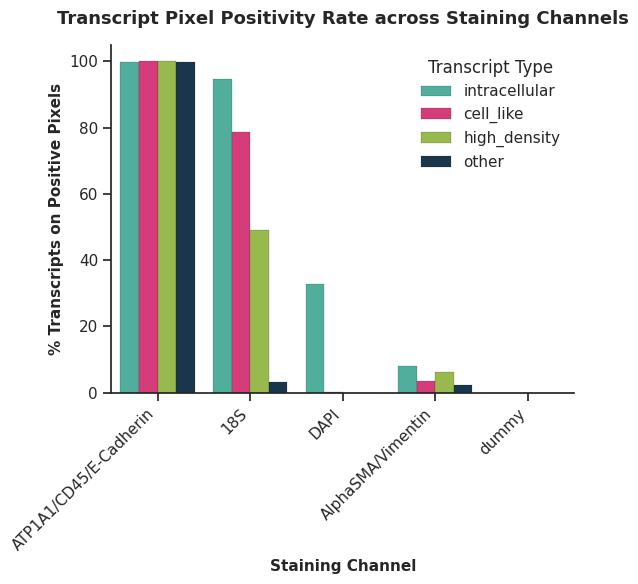

In [179]:
plot_staining_positivity_by_type(
    trans_df=trans_positivity,
    channel_names=channel_names_for_enrichment,
    saving_path=saving_path
)

In [ ]:
Index(['DAPI', 'ATP1A1/CD45/E-Cadherin', '18S', 'AlphaSMA/Vimentin', 'dummy'], dtype='object')

# Downstream_viz


=== [1/6] Transcript Global Ranges (Baseline calculation) ===

=== [2/6] Raw Image Metadata (Scale0) ===

=== [3/6] Extracting and Transforming Cell Boundaries ===

=== [4/6] Processing Transcript Metadata Coloring for Gene: 'Vwf' ===

=== [5/6] Composite Image Channel Processing ===

=== [6/6] Plotting Combined Composite Visualization ===
-> Saved composite PDF: composite_staining_boundaries_Vwf_roi_4300_4800.pdf


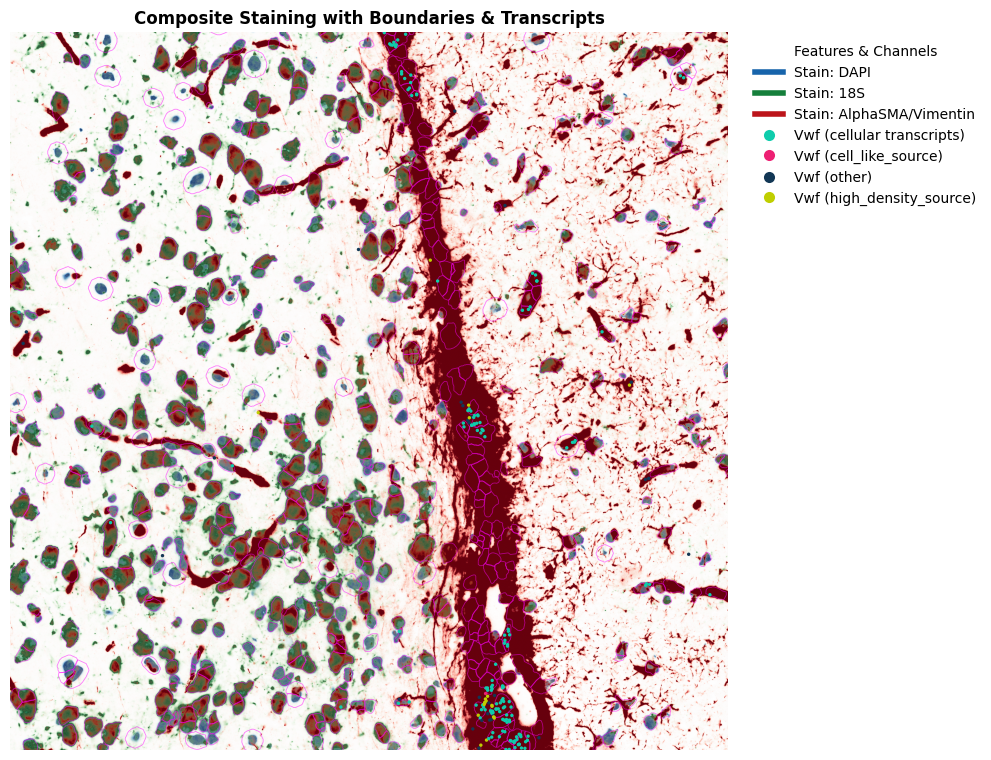

In [93]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4300, 4800, 1000, 1500),
    figsize=(10, 10),
    include_channels=[0, 2, 3],
    cmaps=['Blues', 'Greens', 'Reds'],
    saving_path=saving_path,
    max_pct=90.0,
    
    # Overlay 1 single specific gene colored exactly like spatial_transcripts
    gene_to_plot="Vwf",                     
    color_key="point_source_cellular",       
    shapes_key="cell_boundaries",            
    transcript_colormap="30colors",          
    boundary_linewidth=0.6,
    boundary_color="magenta",                  # High contrast white outlines over dark stains
    boundary_alpha=0.5,
    scatter_size=4.0
)


=== [1/6] Transcript Global Ranges (Baseline calculation) ===

=== [2/6] Raw Image Metadata (Scale0) ===

=== [3/6] Extracting and Transforming Cell Boundaries ===

=== [4/6] Processing Transcript Metadata Coloring for Gene: 'Slc2a1' ===

=== [5/6] Composite Image Channel Processing ===

=== [6/6] Plotting Combined Composite Visualization ===
-> Saved composite PDF: composite_staining_boundaries_Slc2a1_roi_4500_4800.pdf


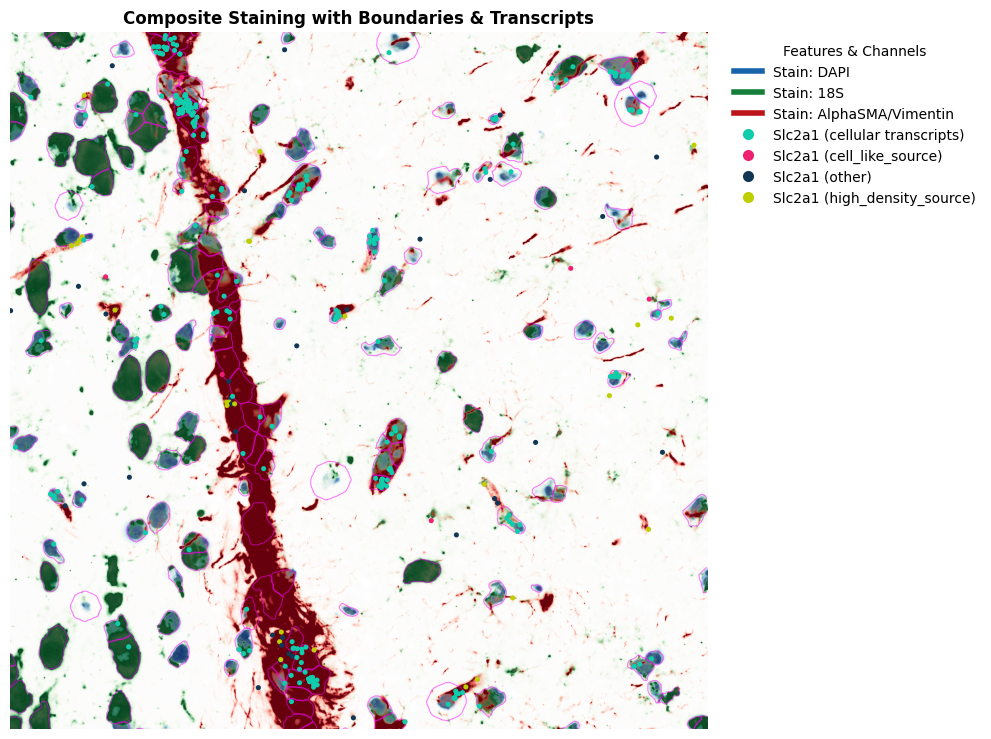

In [94]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,trans_df=transcripts_base_df,
    image_key="morphology_focus",scale_key="scale0",
    roi=(4500, 4800, 1200, 1500),figsize=(10, 10),
    include_channels=[0, 2, 3],cmaps=['Blues', 'Greens', 'Reds'],
    saving_path=saving_path,max_pct=95.0,gene_to_plot="Slc2a1",                     
    color_key="point_source_cellular",shapes_key="cell_boundaries",            
    transcript_colormap="30colors",boundary_linewidth=0.8,
    boundary_color="magenta", boundary_alpha=0.5,scatter_size=9.0)


=== [1/6] Transcript Global Ranges (Baseline calculation) ===

=== [2/6] Raw Image Metadata (Scale0) ===

=== [3/6] Extracting and Transforming Cell Boundaries ===



=== [4/6] Processing Transcript Metadata Coloring for Gene: 'Epas1' ===

=== [5/6] Composite Image Channel Processing ===

=== [6/6] Plotting Combined Composite Visualization ===
-> Saved composite PDF: composite_staining_boundaries_Epas1_roi_3000_4800.pdf


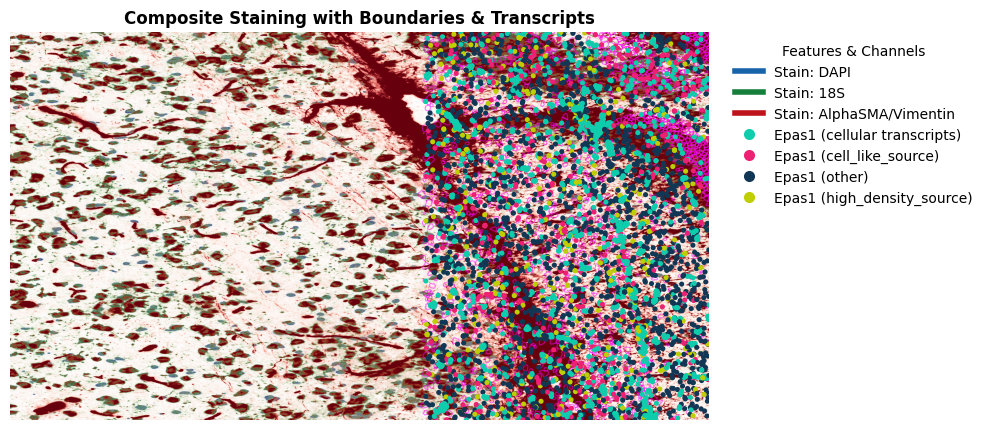

In [96]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,trans_df=transcripts_base_df,
    image_key="morphology_focus",scale_key="scale0",
    roi=(3000, 4800, 1000, 2000),figsize=(10, 10),
    include_channels=[0, 2, 3],cmaps=['Blues', 'Greens', 'Reds'],
    saving_path=saving_path,max_pct=80.0,gene_to_plot="Epas1",                     
    color_key="point_source_cellular",shapes_key="cell_boundaries",            
    transcript_colormap="30colors",boundary_linewidth=0.8,
    boundary_color="magenta", boundary_alpha=0.5,scatter_size=9.0)


=== [1/6] Transcript Global Ranges (Baseline calculation) ===

=== [2/6] Raw Image Metadata (Scale0) ===

=== [3/6] Extracting and Transforming Cell Boundaries ===

=== [4/6] Processing Transcript Metadata Coloring for Gene: 'Slc2a1' ===

=== [5/6] Composite Image Channel Processing ===

=== [6/6] Plotting Combined Composite Visualization ===
-> Saved composite PDF: composite_staining_boundaries_Slc2a1_roi_3500_5000.pdf


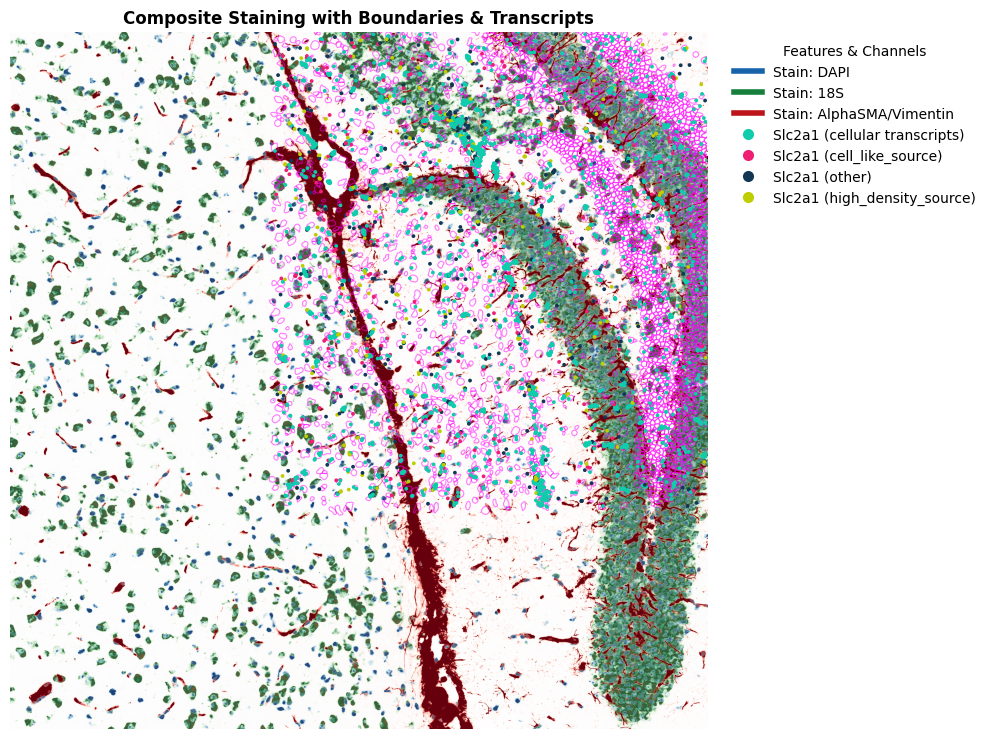

In [55]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,trans_df=transcripts_base_df,
    image_key="morphology_focus",scale_key="scale0",
    roi=(3500, 5000, 500, 2000),figsize=(10, 10),
    include_channels=[0, 2, 3],cmaps=['Blues', 'Greens', 'Reds'],
    saving_path=saving_path,max_pct=95.0,gene_to_plot="Slc2a1",                     
    color_key="point_source_cellular",shapes_key="cell_boundaries",            
    transcript_colormap="30colors",boundary_linewidth=0.8,
    boundary_color="magenta", boundary_alpha=0.5,scatter_size=5.0)


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Filtering and overlaying transcript markers for: ['Pltp', 'Slc2a1', 'Epas1']
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_genes_Pltp_Slc2a1_Epas1_intensity_alpha_roi_4300_4800.pdf


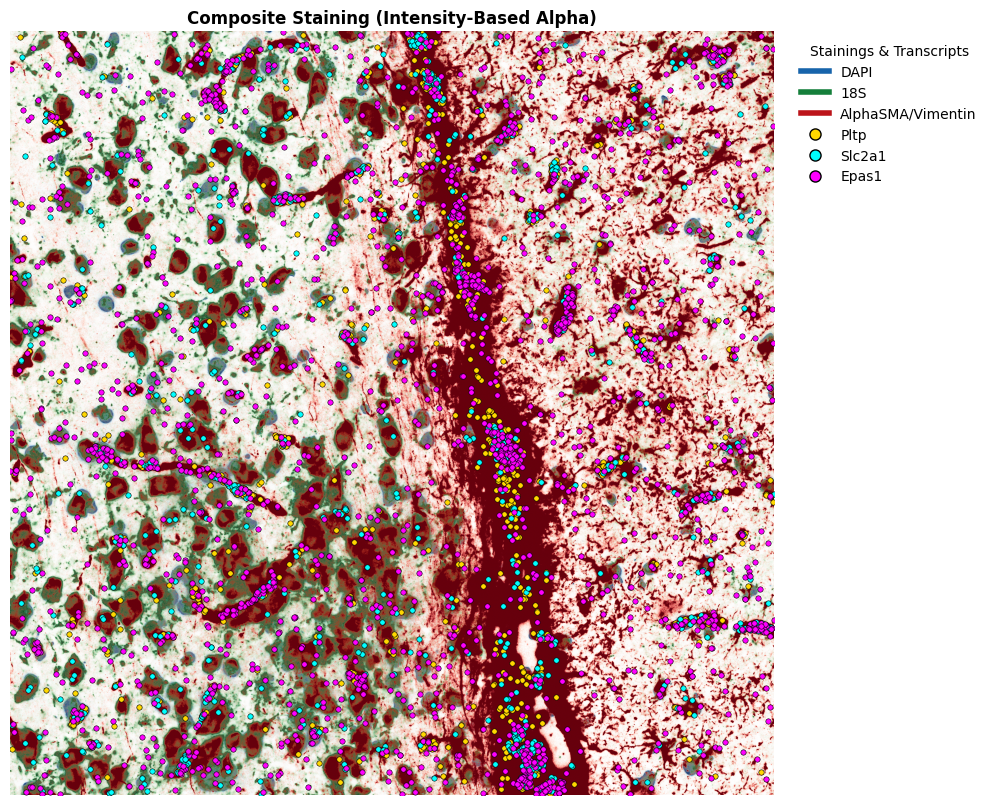


=== [1/5] Transcript Global Ranges (Baseline calculation) ===

=== [2/5] Raw Image Metadata (Scale0) ===

=== [3/5] Scaling Factor Derivation ===

=== [4/5] Composite Processing (Filtering Selected Indices) ===
-> Actively plotting selected channels: ['DAPI', '18S', 'AlphaSMA/Vimentin'] (Indices: [0, 2, 3])

=== [5/5] Plotting Intensity-Alpha Blended Figure ===
-> Filtering and overlaying transcript markers for: ['Pltp', 'Slc2a1', 'Epas1']
-> Intensity-alpha composite PDF saved: staining_composite_channels_0_2_3_genes_Pltp_Slc2a1_Epas1_intensity_alpha_roi_4500_4800.pdf


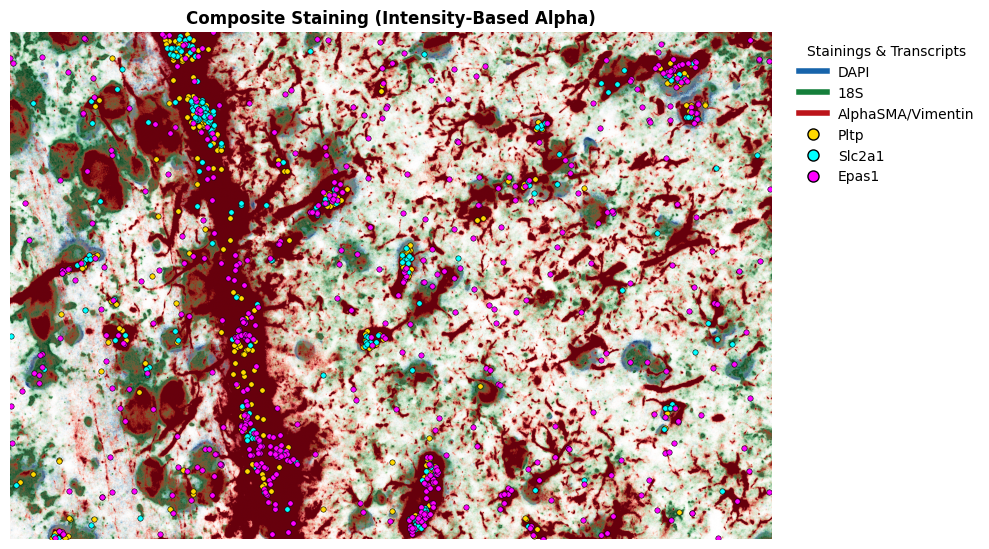

In [46]:
visualize_composite_staining_intensity_alpha(
    sdata=sdata,
    trans_df=transcripts_base_df,
    image_key="morphology_focus",
    scale_key="scale0",
    roi=(4500, 4800, 1300, 1500),
    figsize=(10, 10),
    include_channels=[0, 2, 3],               # Target background array selection
    cmaps=['Blues', 'Greens', 'Reds'],        # Continuous colormaps matching channels
    saving_path=saving_path,
    max_pct=80.0,
    
    # --- New Transcript Overlay Options ---
    genes_to_plot=["Pltp","Slc2a1",'Epas1'], # Replace with your actual target gene string tags
    gene_colors=["#FFD700", "#00FFFF", "#FF00FF"], # Optional explicit HEX color overrides
    gene_size=15                              # Control dot size exposure over intensities
)

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

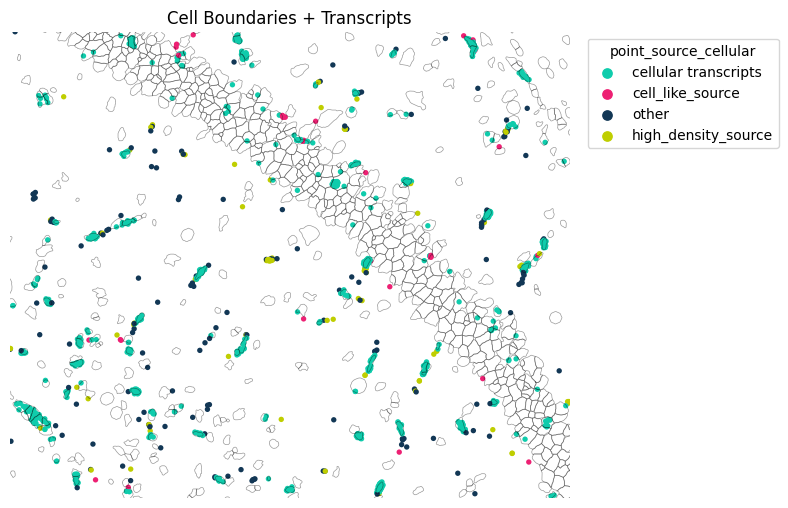

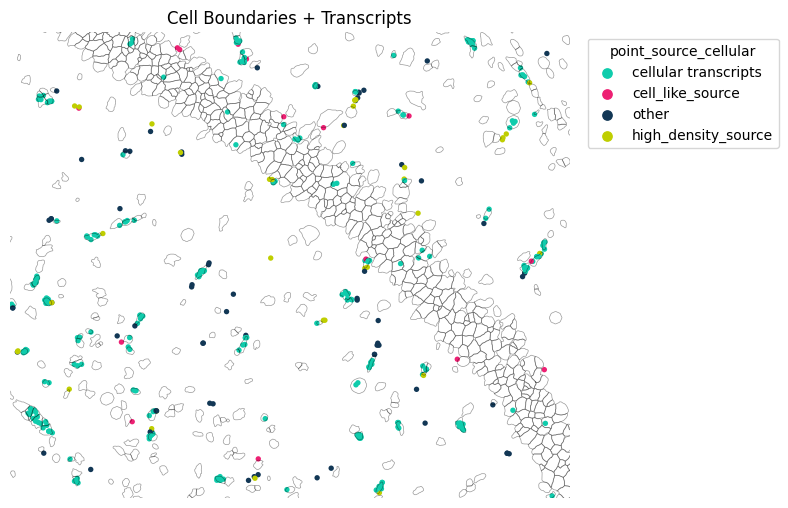

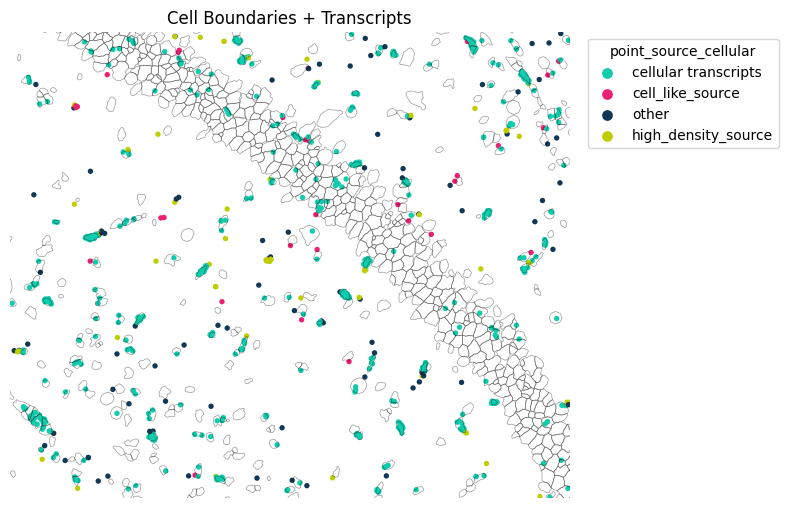

In [172]:
pl.spatial_transcripts(sdata,gene_list=['Pltp'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)
pl.spatial_transcripts(sdata,gene_list=['Flt1'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)
pl.spatial_transcripts(sdata,gene_list=['Slc2a1'],use_roi=True, roi=(4900, 5500, 2100, 2600),scatter_size=10)